## TỔNG QUAN
### Mục tiêu

Xác định và đo lượng các yếu tố tác động đến mức độ hài lòng của khán giả đối với phim, từ đó trả lời câu hỏi: "Yếu tố nào quan trọng nhất? Ảnh hưởng bao nhiêu? Có khác biệt giữa các nhóm không?"

### Output cuối cùng
Bảng xếp hạng yếu tố quan trọng nhất (Top 10-15)
Biểu đồ thể hiện mức độ ảnh hưởng của từng yếu tố
Insights về sự khác biệt giữa các segments
Khuyến nghị cho nhà sản xuất/platform

In [74]:
import pandas as pd
import numpy as np
import re
import json
import ast
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import warnings

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MultiLabelBinarizer
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, silhouette_score, accuracy_score

from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

# Models
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor

import xgboost as xgb
import shap
from sklearn.metrics import mean_squared_error


In [75]:
warnings.filterwarnings('ignore')

# --- 1. ĐỊNH NGHĨA HÀM XỬ LÝ ---
def clean_movielens_title(text):
    return re.sub(r'\s*\(\d{4}\)$', '', str(text)).lower().strip()

def clean_tmdb_title(text):
    return str(text).lower().strip()

def get_director(text):
    try:
        data = ast.literal_eval(text)
        for x in data:
            if x['job'] == 'Director': return x['name']
        return np.nan
    except: return np.nan

def get_top_actors(text):
    try:
        data = ast.literal_eval(text)
        return [x['name'] for x in data[:3]]
    except: return []

### Tổng quan về bộ dữ liệu TMDB và Movielens

#### Bộ dữ liệu TMDB (Đặc điểm phim)

- Yếu tố định lượng (Numerical):
    - budget – Ngân sách sản xuất phim
    - revenue – Doanh thu phòng vé
    - runtime – Thời lượng phim (phút)
    - popularity – Chỉ số độ phổ biến trên TMDB
    - vote_count – Số lượng lượt đánh giá
    - vote_average - Điểm trung bình TMDB
    - vote_average – Điểm đánh giá trung bình trên TMDB

- Yếu tố định tính (Categorical):
    - genres (JSON) – Danh sách thể loại phim (Action, Drama, Comedy, …)
    - production_companies (JSON) – Các hãng sản xuất
    - production_countries (JSON) – Quốc gia sản xuất
    - original_language – Ngôn ngữ gốc của phim
    - status – Trạng thái phát hành (Released, Post Production, …)

- Yếu tố mô tả nội dung:
    - overview – Tóm tắt nội dung phim
    - tagline – Khẩu hiệu phim
    - keywords (JSON) – Tập từ khóa mô tả nội dung

- Yếu tố nhân sự:
    - cast (JSON) – Danh sách diễn viên
    - crew (JSON) – Danh sách ê-kíp sản xuất (đạo diễn, biên kịch, …)

- Biến dẫn xuất / biến xử lý thêm (Feature Engineering):
    - release_year – Năm phát hành (trích từ release_date)
    - ROI = revenue / budget – Tỷ suất lợi nhuận (đại diện cho mức độ thành công thương mại)
    - num_genres – Số lượng thể loại của mỗi phim
    - num_keywords – Số lượng từ khóa
    - cast_size – Số lượng diễn viên tham gia
    - crew_size – Quy mô ê-kíp sản xuất
    - is_franchise / sequel – Biến nhị phân xác định phim có thuộc chuỗi/phần tiếp theo hay không


In [76]:
# --- 3. XỬ LÝ DỮ LIỆU TMDB ---
try:
    tmdb_cred = pd.read_csv('datasets/tmdb_5000/tmdb_5000_credits.csv', encoding='utf-8')
    tmdb_mov = pd.read_csv('datasets/tmdb_5000/tmdb_5000_movies.csv', encoding='utf-8')
except:
    tmdb_cred = pd.read_csv('datasets/tmdb_5000/tmdb_5000_credits.csv', encoding='latin-1')
    tmdb_mov = pd.read_csv('datasets/tmdb_5000/tmdb_5000_movies.csv', encoding='latin-1')

tmdb_cred.columns = ['movie_id', 'title', 'cast', 'crew']
tmdb_mov = tmdb_mov.rename(columns={'id': 'movie_id'})


In [77]:
print("\n--- Sample TMDB Credits ---")
tmdb_cred.head(3)


--- Sample TMDB Credits ---


,movie_id,title,cast,crew
0,19995,Avatar,"[{""cast_id"": 242, ""character"": ""Jake Sully"", ""...","[{""credit_id"": ""52fe48009251416c750aca23"", ""de..."
1,285,Pirates of the Caribbean: At World's End,"[{""cast_id"": 4, ""character"": ""Captain Jack Spa...","[{""credit_id"": ""52fe4232c3a36847f800b579"", ""de..."
2,206647,Spectre,"[{""cast_id"": 1, ""character"": ""James Bond"", ""cr...","[{""credit_id"": ""54805967c3a36829b5002c41"", ""de..."


In [78]:
print("\n--- Sample TMDB Movies ---")
tmdb_mov.head(3)


--- Sample TMDB Movies ---


,budget,genres,homepage,movie_id,keywords,original_language,original_title,overview,popularity,production_companies,production_countries,release_date,revenue,runtime,spoken_languages,status,tagline,title,vote_average,vote_count
0,237000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.avatarmovie.com/,19995,"[{""id"": 1463, ""name"": ""culture clash""}, {""id"":...",en,Avatar,"In the 22nd century, a paraplegic Marine is di...",150.437577,"[{""name"": ""Ingenious Film Partners"", ""id"": 289...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2009-12-10,2787965087,162.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}, {""iso...",Released,Enter the World of Pandora.,Avatar,7.2,11800
1,300000000,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""...",http://disney.go.com/disneypictures/pirates/,285,"[{""id"": 270, ""name"": ""ocean""}, {""id"": 726, ""na...",en,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...",139.082615,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2007-05-19,961000000,169.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"At the end of the world, the adventure begins.",Pirates of the Caribbean: At World's End,6.9,4500
2,245000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.sonypictures.com/movies/spectre/,206647,"[{""id"": 470, ""name"": ""spy""}, {""id"": 818, ""name...",en,Spectre,A cryptic message from Bond’s past sends him o...,107.376788,"[{""name"": ""Columbia Pictures"", ""id"": 5}, {""nam...","[{""iso_3166_1"": ""GB"", ""name"": ""United Kingdom""...",2015-10-26,880674609,148.0,"[{""iso_639_1"": ""fr"", ""name"": ""Fran\u00e7ais""},...",Released,A Plan No One Escapes,Spectre,6.3,4466


In [79]:
# Đổi tên cột title của credits thành 'tittle_cr' để không trùng với 'title' của bảng movies
tmdb_cred.columns = ['movie_id', 'tittle_cr', 'cast', 'crew'] 

tmdb_mov = tmdb_mov.rename(columns={'id': 'movie_id'})

# Merge nội bộ TMDB
tmdb_full = pd.merge(tmdb_mov, tmdb_cred, on='movie_id')

print(f"Loaded & Merged TMDB: {tmdb_full.shape}")

Loaded & Merged TMDB: (4803, 23)


In [80]:
tmdb_full.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4803 entries, 0 to 4802
Data columns (total 23 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   budget                4803 non-null   int64  
 1   genres                4803 non-null   object 
 2   homepage              1712 non-null   object 
 3   movie_id              4803 non-null   int64  
 4   keywords              4803 non-null   object 
 5   original_language     4803 non-null   object 
 6   original_title        4803 non-null   object 
 7   overview              4800 non-null   object 
 8   popularity            4803 non-null   float64
 9   production_companies  4803 non-null   object 
 10  production_countries  4803 non-null   object 
 11  release_date          4802 non-null   object 
 12  revenue               4803 non-null   int64  
 13  runtime               4801 non-null   float64
 14  spoken_languages      4803 non-null   object 
 15  status               

#### Bộ dữ liệu Movielens (Hàng vi người dùng)

Biến phụ thuộc (Target):
    - rating - Điểm đánh giá (0 - 5)

- Yếu tố người dùng:
    - age - Tuổi người dùng
    - gender - Giới tính
    - occupation - Nghề nghiệp
    - user_avg_rating - Điểm trung bình của user

- Yếu tố phim (từ MovieLens)
    - genres – Thể loại phim (có thể đa thể loại)

- Yếu tố tương tác:
    - timestamp - Thời điểm đánh giá

- Biến tổng hợp theo người dùng & phim
    - Hành vi người dùng
        - rating_count_per_user – Tổng số phim mà người dùng đã đánh giá
        - user_avg_rating – Điểm đánh giá trung bình của người dùng

    - Mức độ tương tác của phim
        - total_ratings – Tổng số lượt đánh giá của mỗi phim
        - rating_std – Độ lệch chuẩn điểm đánh giá (mức độ phân hóa ý kiến khán giả)

In [81]:
# --- 2. TẢI DỮ LIỆU ---
print("Đang tải dữ liệu...")
u_cols = ['UserID', 'Gender', 'Age', 'Occupation', 'Zip-code']
m_cols = ['MovieID', 'Title', 'Genres']
r_cols = ['UserID', 'MovieID', 'Rating', 'Timestamp']

users = pd.read_csv('datasets/movie_len_1M/users.dat', sep='::', names=u_cols, encoding='latin-1', engine='python')
movies = pd.read_csv('datasets/movie_len_1M/movies.dat', sep='::', names=m_cols, encoding='latin-1', engine='python')
ratings = pd.read_csv('datasets/movie_len_1M/ratings.dat', sep='::', names=r_cols, encoding='latin-1', engine='python')

Đang tải dữ liệu...


In [82]:
# --- 3. HIỂN THỊ DỮ LIỆU MẪU ĐỂ KIỂM TRA ---

print("\n--- Sample Users ---")
users.head(3)


--- Sample Users ---


,UserID,Gender,Age,Occupation,Zip-code
0,1,F,1,10,48067
1,2,M,56,16,70072
2,3,M,25,15,55117


In [83]:
print("\n--- Sample Movies ---")
movies.head(3)


--- Sample Movies ---


,MovieID,Title,Genres
0,1,Toy Story (1995),Animation|Children's|Comedy
1,2,Jumanji (1995),Adventure|Children's|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance


In [84]:
print("\n--- Sample Ratings ---")
ratings.head(3)


--- Sample Ratings ---


,UserID,MovieID,Rating,Timestamp
0,1,1193,5,978300760
1,1,661,3,978302109
2,1,914,3,978301968


In [85]:
# --- TÍNH ĐIỂM TRUNG BÌNH (AVG_RATING) ---
print("Đang tính toán điểm trung bình cho từng phim...")
movie_targets = ratings.groupby('MovieID')['Rating'].mean().reset_index()
movie_targets.columns = ['MovieID', 'avg_rating']

Đang tính toán điểm trung bình cho từng phim...


In [86]:
print("\n--- Sample Targets Movielens ---")
movie_targets.head(3)


--- Sample Targets Movielens ---


,MovieID,avg_rating
0,1,4.146846
1,2,3.201141
2,3,3.016736


## Tiền xử lý dữ liệu (Data Preprocessing)

Sau khi gộp bảng Movies và Credits, một số biến trong TMDB vẫn ở dạng JSON 
(danh sách các đối tượng).

In [87]:
def json_to_pipe(x, key='name'):
    """
    Chuyển JSON (list of dict) thành chuỗi 'a|b|c'
    """
    if pd.isna(x):
        return ''
    try:
        data = ast.literal_eval(x)
        if isinstance(data, list):
            return '|'.join([item[key] for item in data if key in item])
        return ''
    except:
        return ''

In [88]:
# Kiểm tra xem cột title có tồn tại không
if 'title' not in tmdb_full.columns:
    # Trường hợp file gốc dùng 'original_title', ta tạo lại cột title
    if 'original_title' in tmdb_full.columns:
        tmdb_full['title'] = tmdb_full['original_title']

print(f"Cột trong TMDB Full: {list(tmdb_full.columns)}") 
# Bây giờ chắc chắn đã có cột 'title'

Cột trong TMDB Full: ['budget', 'genres', 'homepage', 'movie_id', 'keywords', 'original_language', 'original_title', 'overview', 'popularity', 'production_companies', 'production_countries', 'release_date', 'revenue', 'runtime', 'spoken_languages', 'status', 'tagline', 'title', 'vote_average', 'vote_count', 'tittle_cr', 'cast', 'crew']


In [89]:
# --- 4. MERGE METADATA ---
print("Đang xử lý Metadata phim...")

# Tạo khóa nối
movies['title_join'] = movies['Title'].apply(clean_movielens_title)
tmdb_full['title_join'] = tmdb_full['title'].apply(clean_tmdb_title)

# Ghép Movies gốc với TMDB
movies_meta = pd.merge(movies, tmdb_full, on='title_join', how='inner')

# Ghép thêm cột avg_rating (từ bảng movie_targets đã tạo ở bước trước)
movies_meta = pd.merge(movies_meta, movie_targets, on='MovieID', how='inner')


Đang xử lý Metadata phim...


### Trích xuất đặc trưng (Feature Selection)

In [90]:
# Trích xuất Director, Actors, Year
movies_meta['director'] = movies_meta['crew'].apply(get_director)
movies_meta['actors_temp'] = movies_meta['cast'].apply(get_top_actors)
actors_df = movies_meta['actors_temp'].apply(pd.Series).iloc[:, :3]
actors_df.columns = ['actor_1', 'actor_2', 'actor_3']
movies_meta = pd.concat([movies_meta, actors_df], axis=1)
movies_meta['release_year'] = movies_meta['Title'].str.extract(r'\((\d{4})\)$').astype(float)

# Chọn lọc các cột metadata????
cols_meta = [
    'MovieID', 'Title', 'Genres', 'release_year', 'avg_rating', 
    'director', 'actor_1', 'actor_2', 'actor_3',
    'budget', 'revenue', 'vote_average', 'vote_count', 'popularity', 'runtime'
]
movies_final_meta = movies_meta[cols_meta]

movies_final_meta.head(5)

,MovieID,Title,Genres,release_year,avg_rating,director,actor_1,actor_2,actor_3,budget,revenue,vote_average,vote_count,popularity,runtime
0,1,Toy Story (1995),Animation|Children's|Comedy,1995.0,4.146846,John Lasseter,Tom Hanks,Tim Allen,Don Rickles,30000000,373554033,7.7,5269,73.640445,81.0
1,10,GoldenEye (1995),Action|Adventure|Thriller,1995.0,3.540541,Martin Campbell,Pierce Brosnan,Sean Bean,Izabella Scorupco,58000000,352194034,6.6,1174,59.824565,130.0
2,14,Nixon (1995),Drama,1995.0,3.542484,Oliver Stone,Anthony Hopkins,Joan Allen,Powers Boothe,44000000,13681765,7.1,71,3.770161,192.0
3,15,Cutthroat Island (1995),Action|Adventure|Romance,1995.0,2.458904,Renny Harlin,Geena Davis,Matthew Modine,Frank Langella,98000000,10017322,5.7,136,7.029308,119.0
4,16,Casino (1995),Drama|Thriller,1995.0,3.793255,Martin Scorsese,Robert De Niro,Sharon Stone,Joe Pesci,52000000,116112375,7.8,1307,40.066880,178.0


In [91]:
# --- 5. TẠO DATAFRAME CUỐI CÙNG ---
print("Đang ghép vào bảng Ratings gốc...")
df_final = pd.merge(ratings, movies_final_meta, on='MovieID', how='inner')

print("-" * 30)
print(f"Kích thước cuối cùng: {df_final.shape}")
print("5 dòng đầu tiên:")
# print(df_final[['UserID', 'Title', 'Rating', 'avg_rating', 'vote_average']].head())
df_final.head(3)

Đang ghép vào bảng Ratings gốc...
------------------------------
Kích thước cuối cùng: (450575, 18)
5 dòng đầu tiên:


,UserID,MovieID,Rating,Timestamp,Title,Genres,release_year,avg_rating,director,actor_1,actor_2,actor_3,budget,revenue,vote_average,vote_count,popularity,runtime
0,1,1193,5,978300760,One Flew Over the Cuckoo's Nest (1975),Drama,1975.0,4.390725,Miloš Forman,Jack Nicholson,Louise Fletcher,Danny DeVito,3000000,108981275,8.2,2919,127.525581,133.0
1,1,914,3,978301968,My Fair Lady (1964),Musical|Romance,1964.0,4.154088,George Cukor,Audrey Hepburn,Rex Harrison,Stanley Holloway,17000000,72070731,7.4,352,20.786616,170.0
2,1,3408,4,978300275,Erin Brockovich (2000),Drama,2000.0,3.863878,Steven Soderbergh,Julia Roberts,Albert Finney,Aaron Eckhart,52000000,256271286,7.1,716,30.347332,131.0


### Tích hợp dữ liệu (Data Integration)

In [92]:
# --- TỐI ƯU HÓA TRƯỚC KHI MERGE ---

# 1. Chọn lọc các cột cần thiết từ bảng phim (Metadata)
# Chúng ta chỉ giữ lại những thông tin có giá trị phân tích
cols_to_keep = [
    'MovieID', 'Title',             # Định danh phim
    'Genres', 'release_year',       # Thông tin cơ bản
    'director', 'actor_1', 'actor_2', 'actor_3', # Ekip làm phim
    'budget', 'revenue',            # Tài chính
    'vote_average', 'vote_count',   # Đánh giá từ TMDB
    'avg_rating',                    # Đánh giá trung bình từ MovieLens (Đã tính ở bước trước)
    'runtime', 'popularity'
]

# Lọc để chỉ lấy các cột thực sự tồn tại trong movies_merged (tránh lỗi nếu thiếu cột nào đó)
existing_cols = [c for c in cols_to_keep if c in movies_final_meta.columns]
movies_lean = movies_final_meta[existing_cols]


In [93]:
# 2. Thực hiện Merge cuối cùng (Big Merge)
# Ghép bảng Ratings (1 triệu dòng) với bảng Metadata phim đã lọc gọn
# Dùng 'inner' để chỉ giữ lại các rating của những phim ĐÃ CÓ thông tin từ TMDB
print("Đang thực hiện ghép dữ liệu cuối cùng (sẽ mất một chút thời gian)...")
full_data = pd.merge(ratings, movies_lean, on='MovieID', how='inner')

Đang thực hiện ghép dữ liệu cuối cùng (sẽ mất một chút thời gian)...


In [94]:

# --- 3. KIỂM TRA KẾT QUẢ ---
print("-" * 30)
print(f"Tổng số lượt đánh giá gốc (Ratings): {ratings.shape[0]}")
print(f"Tổng số dòng dữ liệu sau khi merge (Full Data): {full_data.shape[0]}")
print(f"-> Số lượng đánh giá bị loại bỏ (do phim không khớp TMDB): {ratings.shape[0] - full_data.shape[0]}")
print("-" * 30)

# Xem 5 dòng dữ liệu hoàn chỉnh để đảm bảo bạn có đủ 3 loại điểm số
# 1. Rating: Điểm do người dùng này chấm
# 2. avg_rating: Điểm trung bình của phim trên MovieLens
# 3. vote_average: Điểm trung bình của phim trên TMDB
print("5 dòng dữ liệu mẫu (Check đủ 3 cột điểm):")
cols_check = ['UserID', 'Title', 'Rating', 'avg_rating', 'vote_average', 'director']
full_data[cols_check].head()

------------------------------
Tổng số lượt đánh giá gốc (Ratings): 1000209
Tổng số dòng dữ liệu sau khi merge (Full Data): 450575
-> Số lượng đánh giá bị loại bỏ (do phim không khớp TMDB): 549634
------------------------------
5 dòng dữ liệu mẫu (Check đủ 3 cột điểm):


,UserID,Title,Rating,avg_rating,vote_average,director
0,1,One Flew Over the Cuckoo's Nest (1975),5,4.390725,8.2,Miloš Forman
1,1,My Fair Lady (1964),3,4.154088,7.4,George Cukor
2,1,Erin Brockovich (2000),4,3.863878,7.1,Steven Soderbergh
3,1,Ben-Hur (1959),5,4.110795,5.3,Timur Bekmambetov
4,1,Snow White and the Seven Dwarfs (1937),4,3.845347,6.9,David Hand


In [95]:
full_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 450575 entries, 0 to 450574
Data columns (total 18 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   UserID        450575 non-null  int64  
 1   MovieID       450575 non-null  int64  
 2   Rating        450575 non-null  int64  
 3   Timestamp     450575 non-null  int64  
 4   Title         450575 non-null  object 
 5   Genres        450575 non-null  object 
 6   release_year  450575 non-null  float64
 7   director      450535 non-null  object 
 8   actor_1       450535 non-null  object 
 9   actor_2       450535 non-null  object 
 10  actor_3       450535 non-null  object 
 11  budget        450575 non-null  int64  
 12  revenue       450575 non-null  int64  
 13  vote_average  450575 non-null  float64
 14  vote_count    450575 non-null  int64  
 15  avg_rating    450575 non-null  float64
 16  runtime       450575 non-null  float64
 17  popularity    450575 non-null  float64
dtypes: f

In [96]:
full_data.head()

,UserID,MovieID,Rating,Timestamp,Title,Genres,release_year,director,actor_1,actor_2,actor_3,budget,revenue,vote_average,vote_count,avg_rating,runtime,popularity
0,1,1193,5,978300760,One Flew Over the Cuckoo's Nest (1975),Drama,1975.0,Miloš Forman,Jack Nicholson,Louise Fletcher,Danny DeVito,3000000,108981275,8.2,2919,4.390725,133.0,127.525581
1,1,914,3,978301968,My Fair Lady (1964),Musical|Romance,1964.0,George Cukor,Audrey Hepburn,Rex Harrison,Stanley Holloway,17000000,72070731,7.4,352,4.154088,170.0,20.786616
2,1,3408,4,978300275,Erin Brockovich (2000),Drama,2000.0,Steven Soderbergh,Julia Roberts,Albert Finney,Aaron Eckhart,52000000,256271286,7.1,716,3.863878,131.0,30.347332
3,1,1287,5,978302039,Ben-Hur (1959),Action|Adventure|Drama,1959.0,Timur Bekmambetov,Jack Huston,Toby Kebbell,Rodrigo Santoro,100000000,94061311,5.3,621,4.110795,125.0,29.608322
4,1,594,4,978302268,Snow White and the Seven Dwarfs (1937),Animation|Children's|Musical,1937.0,David Hand,Adriana Caselotti,Lucille La Verne,Harry Stockwell,1488423,184925486,6.9,1914,3.845347,83.0,80.171283


In [97]:
# --- BƯỚC 1: GOM NHÓM DỮ LIỆU THEO PHIM ---
# Tính điểm trung bình thực tế của người dùng MovieLens cho từng phim
movie_comparison = full_data.groupby('Title').agg({
    'Rating': 'mean',          # Điểm trung bình MovieLens (1-5)
    'vote_average': 'first',   # Điểm TMDB (0-10) - Lấy giá trị đầu tiên vì nó giống nhau cho cả phim
    'vote_count': 'first'   # Lấy số lượng vote để lọc bớt phim ít người xem
}).reset_index()

# Đổi tên cho dễ gọi
movie_comparison.columns = ['Title', 'ML_Score', 'TMDB_Score', 'Vote_Count']

In [98]:
movie_comparison.head()

,Title,ML_Score,TMDB_Score,Vote_Count
0,10 Things I Hate About You (1999),3.422857,7.3,1701
1,12 Angry Men (1957),4.295455,8.2,2078
2,20 Dates (1998),2.856115,3.7,3
3,"20,000 Leagues Under the Sea (1954)",3.702609,6.8,157
4,200 Cigarettes (1999),2.883978,6.1,44


In [99]:
# --- BƯỚC 2: CHUẨN HÓA THANG ĐIỂM ---
# Chuyển TMDB từ thang 10 về thang 5 để so sánh công bằng
movie_comparison['TMDB_Score_Norm'] = movie_comparison['TMDB_Score'] / 2

# Lọc các phim có ít nhất 50 lượt đánh giá để biểu đồ không bị nhiễu
movie_comparison = movie_comparison[movie_comparison['Vote_Count'] > 50]


In [100]:
movie_comparison.head()

,Title,ML_Score,TMDB_Score,Vote_Count,TMDB_Score_Norm
0,10 Things I Hate About You (1999),3.422857,7.3,1701,3.65
1,12 Angry Men (1957),4.295455,8.2,2078,4.10
3,"20,000 Leagues Under the Sea (1954)",3.702609,6.8,157,3.40
5,2001: A Space Odyssey (1968),4.068765,7.9,2998,3.95
7,28 Days (2000),3.065347,6.0,208,3.00


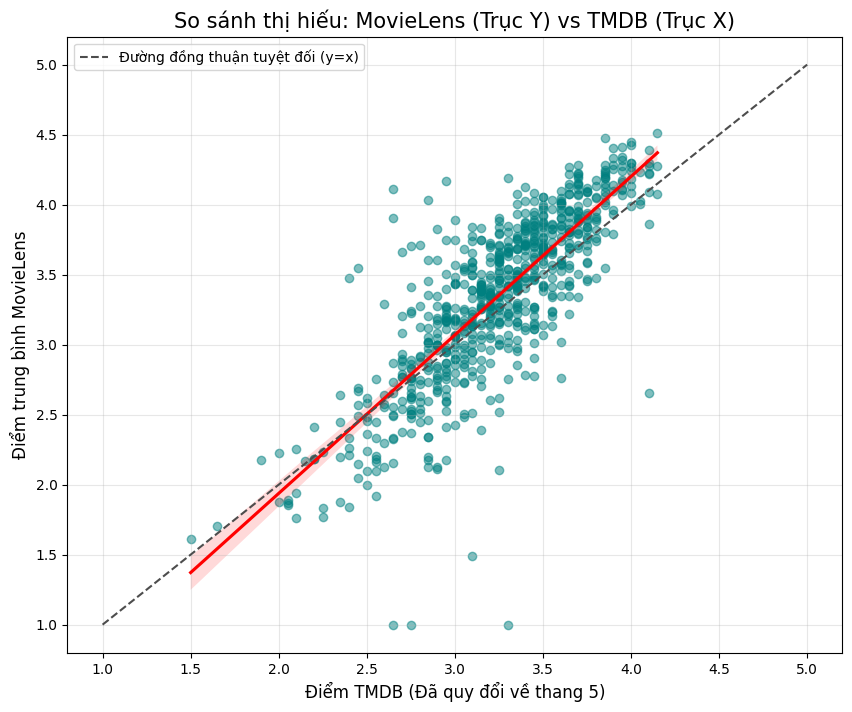

In [101]:

# --- BƯỚC 3: VẼ BIỂU ĐỒ TƯƠNG QUAN ---
plt.figure(figsize=(10, 8))

# Vẽ Scatter plot kèm đường hồi quy (Regplot)
sns.regplot(x='TMDB_Score_Norm', y='ML_Score', data=movie_comparison,
            scatter_kws={'alpha': 0.5, 'color': 'teal'}, 
            line_kws={'color': 'red'})

# Vẽ đường chéo y=x (Đường tham chiếu sự hoàn hảo)
# Nếu điểm nằm trên đường này: MovieLens và TMDB chấm y hệt nhau
plt.plot([1, 5], [1, 5], ls="--", c=".3", label="Đường đồng thuận tuyệt đối (y=x)")

plt.title('So sánh thị hiếu: MovieLens (Trục Y) vs TMDB (Trục X)', fontsize=15)
plt.xlabel('Điểm TMDB (Đã quy đổi về thang 5)', fontsize=12)
plt.ylabel('Điểm trung bình MovieLens', fontsize=12)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Biểu đồ thể hiện mối quan hệ giữa điểm đánh giá trung bình của người dùng MovieLens (trục Y) và điểm đánh giá của TMDB đã quy đổi về thang điểm 5 (trục X).

1️⃣ Xu hướng chung: tương quan dương rõ rệt

Các điểm dữ liệu phân bố theo xu hướng đi lên, bám khá sát đường hồi quy màu đỏ.

Điều này cho thấy:

Những bộ phim được đánh giá cao trên TMDB có xu hướng cũng nhận được điểm đánh giá cao từ người dùng MovieLens.

👉 Có thể kết luận sơ bộ rằng hai hệ thống đánh giá có mức độ đồng thuận nhất định.

2️⃣ So sánh với đường y = x (đồng thuận tuyệt đối)

Đường nét đứt biểu diễn trường hợp TMDB và MovieLens đánh giá hoàn toàn giống nhau.

Quan sát thấy:

Nhiều điểm nằm lệch khỏi đường y = x

Đặc biệt ở vùng điểm trung bình (khoảng 2.5 – 3.5)

📌 Điều này cho thấy:

Mặc dù có tương quan, nhưng TMDB và MovieLens không đánh giá phim theo cùng một chuẩn tuyệt đối.

3️⃣ Sự khác biệt trong hành vi đánh giá

Ở một số khu vực:

TMDB đánh giá khá cao (≈ 3.5 – 4.0)

nhưng MovieLens chỉ đánh giá ở mức trung bình (≈ 3.0 – 3.5)

👉 Gợi ý rằng:

Người dùng MovieLens có xu hướng khắt khe hơn

Hoặc:

TMDB phản ánh thị hiếu đại chúng

MovieLens phản ánh nhóm người dùng “review nghiêm túc” hơn

4️⃣ Độ phân tán và ngoại lệ (outliers)

Có một số điểm:

TMDB đánh giá cao nhưng MovieLens đánh giá thấp (và ngược lại)

Điều này cho thấy:

Một bộ phim có thể thành công về mặt truyền thông / đại chúng nhưng không nhất thiết được cộng đồng người xem đánh giá cao về chất lượng.

📌 Đây chính là động lực nghiên cứu cho đề tài của bạn.

In [102]:

# --- BƯỚC 4: TÌM NHỮNG PHIM "GÂY TRANH CÃI" NHẤT ---
# Tính độ lệch (Gap)
movie_comparison['Diff'] = movie_comparison['ML_Score'] - movie_comparison['TMDB_Score_Norm']

print("--- PHIM MOVIELENS THÍCH HƠN TMDB (Top 5) ---")
print(movie_comparison.sort_values('Diff', ascending=False)[['Title', 'ML_Score', 'TMDB_Score_Norm']].head(5))

print("\n--- PHIM TMDB THÍCH HƠN MOVIELENS (Top 5) ---")
print(movie_comparison.sort_values('Diff', ascending=True)[['Title', 'ML_Score', 'TMDB_Score_Norm']].head(5))

--- PHIM MOVIELENS THÍCH HƠN TMDB (Top 5) ---
                         Title  ML_Score  TMDB_Score_Norm
95              Ben-Hur (1959)  4.110795             2.65
347        Ghostbusters (1984)  3.905548             2.65
701     Shall We Dance? (1937)  4.165714             2.95
29   All the King's Men (1949)  4.033613             2.85
369  Gulliver's Travels (1939)  3.547009             2.45

--- PHIM TMDB THÍCH HƠN MOVIELENS (Top 5) ---
                         Title  ML_Score  TMDB_Score_Norm
834          Underworld (1997)  1.000000             3.30
342         Get Over It (1996)  1.000000             2.75
718           Sleepover (1995)  1.000000             2.65
222  Digimon: The Movie (2000)  1.488372             3.10
628              Psycho (1998)  2.651515             4.10


### Làm sạch dữ liệu (Data Cleaning)

In [103]:
# Kiểm tra dữ liệu bị thiếu (Missing values)
full_data.isnull().sum()

UserID           0
MovieID          0
Rating           0
Timestamp        0
Title            0
Genres           0
release_year     0
director        40
actor_1         40
actor_2         40
actor_3         40
budget           0
revenue          0
vote_average     0
vote_count       0
avg_rating       0
runtime          0
popularity       0
dtype: int64

In [104]:
# XỬ LÝ DỮ LIỆU BỊ THIẾU (XÓA DÒNG)
# inplace=True sẽ thay đổi trực tiếp trên dataframe hiện tại
full_data.dropna(subset=['director', 'actor_1'], inplace=True)

print(f"Đã xóa các dòng Null. Kích thước dữ liệu hiện tại: {full_data.shape}\n Số dòng bị thiếu: \n{full_data.isnull().sum()}")

Đã xóa các dòng Null. Kích thước dữ liệu hiện tại: (450495, 18)
 Số dòng bị thiếu: 
UserID          0
MovieID         0
Rating          0
Timestamp       0
Title           0
Genres          0
release_year    0
director        0
actor_1         0
actor_2         0
actor_3         0
budget          0
revenue         0
vote_average    0
vote_count      0
avg_rating      0
runtime         0
popularity      0
dtype: int64


In [105]:
# Kiểm tra dữ liệu bị trùng lặp
full_data.duplicated().sum()

0

In [106]:
# --- LỌC DỮ LIỆU CHẤT LƯỢNG CAO (CLEANING DATA) ---

print(f"Số lượng dòng dữ liệu ban đầu: {full_data.shape[0]}")

# Áp dụng 3 điều kiện lọc cùng lúc:
# 1. vote_count > 50: Bỏ qua các phim quá ít người quan tâm trên TMDB (tránh nhiễu)
# 2. budget > 10000: Bỏ qua phim không có số liệu ngân sách hoặc ngân sách quá thấp (lỗi nhập liệu)
# 3. revenue > 10000: Bỏ qua phim không có số liệu doanh thu

full_data = full_data[
    (full_data['vote_count'] > 50) & 
    (full_data['budget'] > 10000) & 
    (full_data['revenue'] > 10000)
]

# --- KIỂM TRA KẾT QUẢ SAU KHI LỌC ---
print("-" * 30)
print(f"Số lượng dòng sau khi lọc: {full_data.shape[0]}")
print(f"-> Đã loại bỏ: {full_data.shape[0] - full_data.shape[0]} dòng dữ liệu rác/thiếu thông tin.")

# Xem thống kê nhanh về tài chính của tập dữ liệu sạch
print("\nThống kê dữ liệu tài chính sau khi lọc:")
print(full_data[['budget', 'revenue', 'vote_count']].describe().apply(lambda s: s.apply('{0:.2f}'.format)))

Số lượng dòng dữ liệu ban đầu: 450495
------------------------------
Số lượng dòng sau khi lọc: 397975
-> Đã loại bỏ: 0 dòng dữ liệu rác/thiếu thông tin.

Thống kê dữ liệu tài chính sau khi lọc:
             budget        revenue vote_count
count     397975.00      397975.00  397975.00
mean    37087587.03   180600388.37    1467.37
std     36699190.83   210367425.44    1606.35
min        12000.00      120000.00      52.00
25%     10500000.00    39846344.00     395.00
50%     25000000.00   115101622.00     840.00
75%     55000000.00   254700832.00    1783.00
max    207000000.00  1845034188.00    9413.00


## Khám phá Dữ liệu (EDA - Exploratory Data Analysis)

### Phân tích đơn biến

Câu hỏi cần trả lời:
+ Rating có phân bố chuẩn không? (normal distribution)
+ Có outliers không?
+ Có imbalance trong categorical variables không?

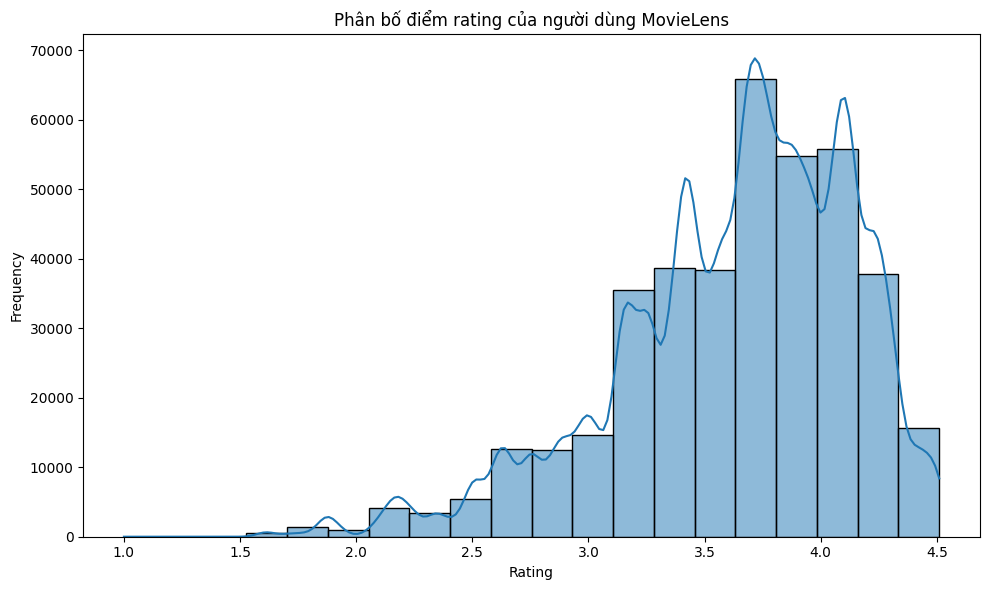

In [107]:
# Phân bố biến mục tiêu
plt.figure(figsize=(10, 6))
sns.histplot(full_data['avg_rating'], bins=20, kde=True)
plt.title('Phân bố điểm rating của người dùng MovieLens')
plt.xlabel('Rating')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()


Biểu đồ phân bố điểm rating cho thấy dữ liệu lệch trái rõ rệt:

+ Tần suất thấp ở các mức điểm thấp (1.0–2.5) và tăng mạnh ở các mức điểm cao. Phần lớn đánh giá tập trung trong khoảng 3.0–4.5, với các cột vượt 30.000 lượt. Đỉnh cao nhất xuất hiện tại mức 4.0, đạt khoảng 65.000–70.000 lượt, tiếp theo là các đỉnh tại 3.0 và 3.5. Sau mức 4.0, tần suất giảm dần ở 4.5. 

+ Đường cong mật độ bám sát các cột và gợn sóng theo các mức điểm nguyên và bán nguyên, phản ánh xu hướng đánh giá tập trung vào các mốc điểm quen thuộc.

In [109]:
# 2. Thống kê mô tả
print(full_data['Rating'].describe())
print(f"Skewness: {full_data['Rating'].skew():.3f}")
print(f"Kurtosis: {full_data['Rating'].kurtosis():.3f}")


count    397975.000000
mean          3.630100
std           1.106728
min           1.000000
25%           3.000000
50%           4.000000
75%           4.000000
max           5.000000
Name: Rating, dtype: float64
Skewness: -0.591
Kurtosis: -0.292


- Kết quả thống kê mô tả cho thấy điểm rating trung bình của người dùng MovieLens đạt 3.63 trên thang điểm 5. 
Giá trị trung vị và tứ phân vị trên đều bằng 4.0, cho thấy phần lớn các bộ phim được đánh giá ở mức khá đến tốt.

- Phân bố rating có độ lệch trái nhẹ (skewness = -0.591), phản ánh xu hướng người dùng chấm điểm cao nhiều hơn điểm thấp.
Hệ số kurtosis âm (-0.293) cho thấy phân bố có đỉnh thấp và trải rộng hơn so với phân bố chuẩn, không xuất hiện hiện tượng tập trung quá mức quanh giá trị trung bình.

- Nhìn chung, phân bố rating không hoàn toàn tuân theo phân bố chuẩn nhưng không có sự lệch cực đoan, cho phép áp dụng các phương pháp phân tích thống kê và mô hình hóa trong các bước tiếp theo.


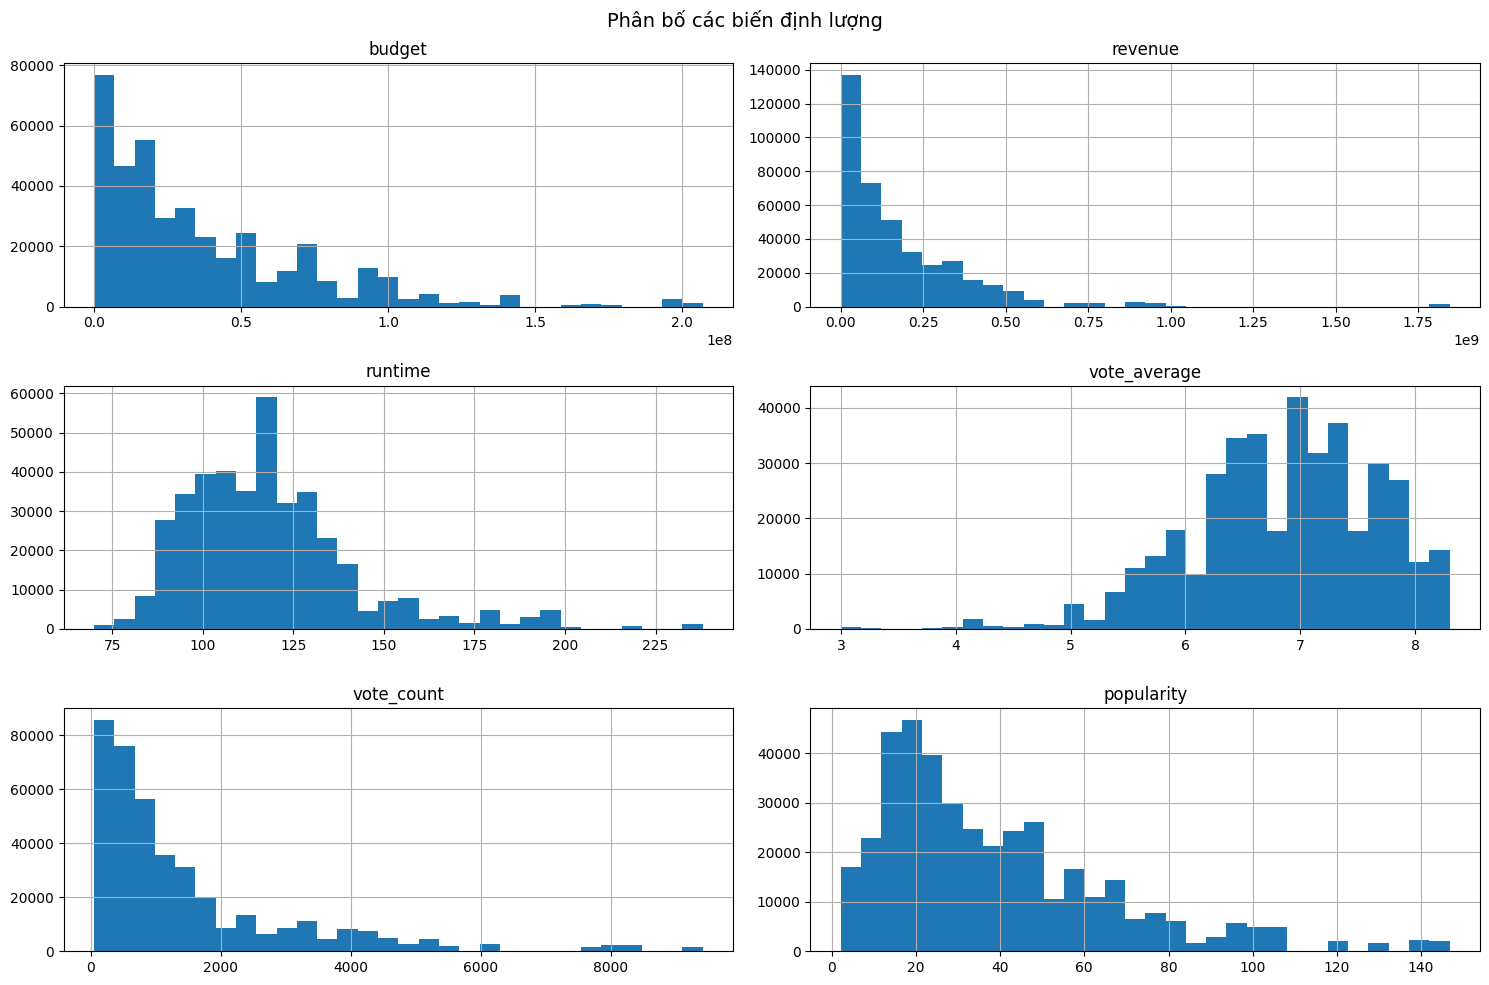

In [126]:
# 3. Phân bố các biến numerical khác
numerical_cols = [
    'budget', 
    'revenue', 
    'runtime', 
    'vote_average', 
    'vote_count',
    'popularity'
]

full_data[numerical_cols].hist(figsize=(15, 10), bins=30)
plt.suptitle('Phân bố các biến định lượng', fontsize=14)
plt.tight_layout()
plt.show()


Nhóm biến lệch phải mạnh (budget, revenue, vote_count, popularity):
Các biến này đều có phân bố lệch phải rõ rệt. Phần lớn phim nằm ở mức thấp đến trung bình, trong khi chỉ một số ít phim bom tấn hoặc rất nổi tiếng có giá trị cực cao, tạo ra đuôi dài. Đây là đặc trưng phổ biến của ngành điện ảnh, phản ánh sự chênh lệch lớn giữa phim đại chúng và số ít tác phẩm dẫn đầu thị trường.

Nhóm biến tập trung và ổn định (runtime):
Thời lượng phim phân bố khá tập trung, gần dạng chuông, chủ yếu trong khoảng 90–130 phút. Điều này cho thấy thời lượng phim điện ảnh tương đối ổn định, chỉ có rất ít phim quá ngắn hoặc quá dài.

Nhóm biến phản ánh cảm nhận người xem (vote_average):
Điểm đánh giá trung bình tập trung nhiều ở khoảng 6–8 điểm, đây là điểm được chấm từ TMDB, cho thấy xu hướng người dùng đánh giá phim khá tích cực. Các mức điểm quá thấp hoặc quá cao xuất hiện ít, phản ánh sự đồng thuận tương đối trong cảm nhận chất lượng phim.

Sự xuất hiện dày đặc của các giá trị ngoại lai (outliers) ở nhóm biến tài chính và mức độ phổ biến chính là minh chứng rõ nét cho phân phối "đuôi dài" (long-tail) đặc thù của ngành công nghiệp điện ảnh. Những giá trị này không phải là nhiễu, mà đại diện cho các bộ phim "bom tấn" nằm tách biệt hoàn toàn so với mặt bằng chung, tạo ra sự chênh lệch cực lớn về quy mô và sức ảnh hưởng. Chính sự hiện diện của những ngoại lai này đã kéo dãn đồ thị về phía bên phải, gây ra hiện tượng lệch phân phối, đòi hỏi các phương pháp xử lý dữ liệu đặc thù để mô hình không bị thiên lệch bởi thiểu số các siêu phẩm này.



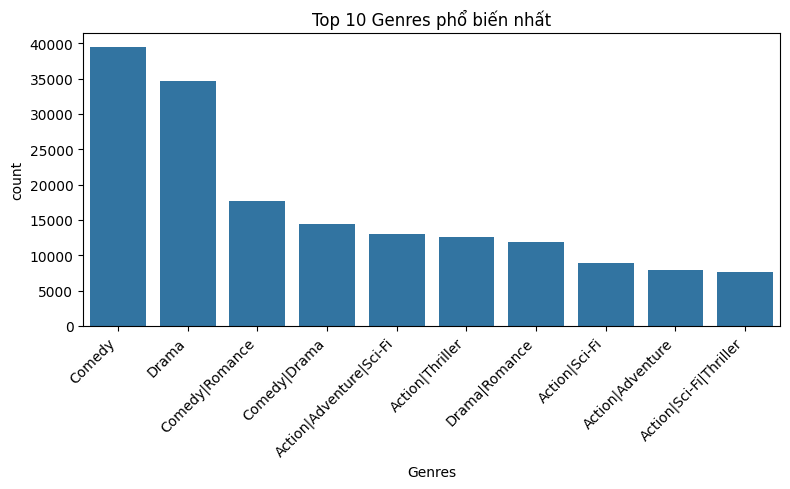

In [135]:
import seaborn as sns
import matplotlib.pyplot as plt

# 4. Tần suất của các biến phân loại
categorical_cols = ['Genres']

for col in categorical_cols:
    top_values = full_data[col].value_counts().head(10).reset_index()
    top_values.columns = [col, 'count']

    plt.figure(figsize=(8, 5))
    sns.barplot(data=top_values, x=col, y='count')
    plt.title(f'Top 10 {col} phổ biến nhất')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

Genres distribution đã xác nhận có tồn tại tình trạng sự mất cân bằng trong biến phân loại (Categorical imbalance). Số lượng phim thuộc thể loại Comedy (gần 40.000) và Drama (gần 35.000) áp đảo hoàn toàn so với các thể loại phức hợp như Action|Sci-Fi|Thriller (chỉ khoảng 7.000). Sự chênh lệch lớn về tần suất xuất hiện giữa các nhóm này chính là biểu hiện rõ nhất của mất cân bằng dữ liệu, điều này sẽ ảnh hưởng lớn nếu dùng Genre làm biến mục tiêu để dự đoán.

### Phân tích hai biến

Insights cần tìm:
+ Biến nào có correlation mạnh với rating?
+ Có non-linear relationships không?
+ Có interaction effects không? (VD: budget cao + action genre = rating cao)

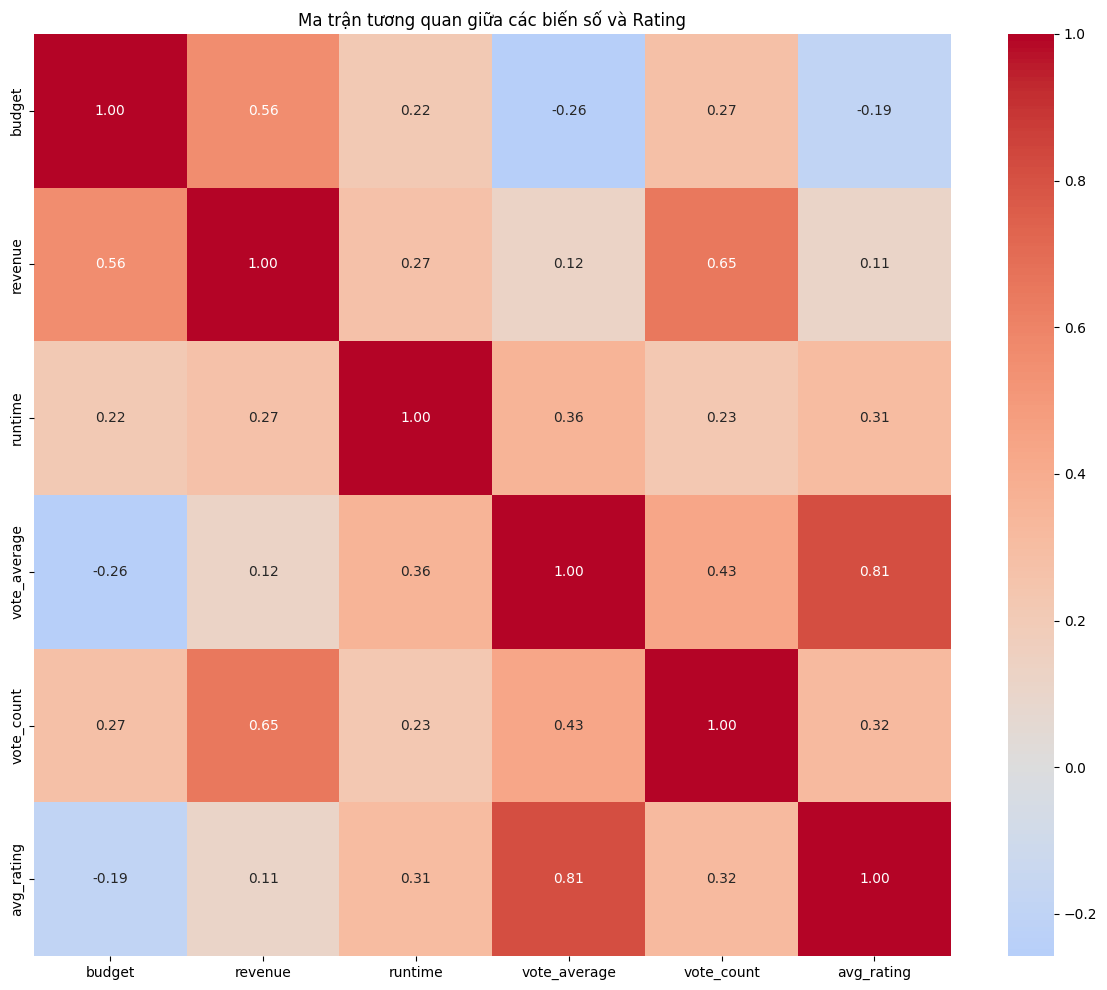

In [111]:
plt.figure(figsize=(12, 10))

corr_cols = numerical_cols + ['avg_rating']
df_movie_scope = full_data.drop_duplicates(subset=['MovieID']).copy()
correlation_matrix = df_movie_scope[corr_cols].corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap='coolwarm',
    center=0
)

plt.title('Ma trận tương quan giữa các biến số và Rating')
plt.tight_layout()
plt.show()


Mối tương quan cùng chiều cực mạnh (0.81) giữa avg_rating và vote_average, khẳng định rằng đánh giá của người dùng trên MovieLens rất đồng nhất với điểm số đại chúng trên TMDB. 

Điểm số trung bình cũng có mối liên hệ tích cực vừa phải với thời lượng phim (0.31) và số lượt bình chọn (0.32), gợi ý rằng các bộ phim có thời lượng dài hơn (thường là phim có chiều sâu) và được nhiều người quan tâm thường có chất lượng tốt hơn.

Ngược lại, các yếu tố tài chính lại cho thấy mối liên hệ rất yếu, thậm chí là tiêu cực với chất lượng phim:

+ Doanh thu (Revenue) gần như không ảnh hưởng đến điểm số (0.11), trong khi ngân sách (Budget) lại có tương quan âm nhẹ (-0.19). Điều này phản ánh một thực tế thú vị: phim được đầu tư "khủng" chưa chắc đã hay, thậm chí đôi khi ngân sách càng cao thì điểm đánh giá lại càng thấp hơn so với kỳ vọng.

+ Sự phụ thuộc lẫn nhau giữa các biến độc lập, chẳng hạn như phim có doanh thu cao thường đi kèm với lượng tương tác lớn (0.65) và ngân sách lớn (0.56).

Mối tương quan 0.31 giữa thời lượng và điểm số gợi mở giả thuyết rằng khán giả thường ưu ái những tác phẩm dài hơi có chiều sâu hơn là phim giải trí ngắn. Dùng boxplot để kiểm chứng:

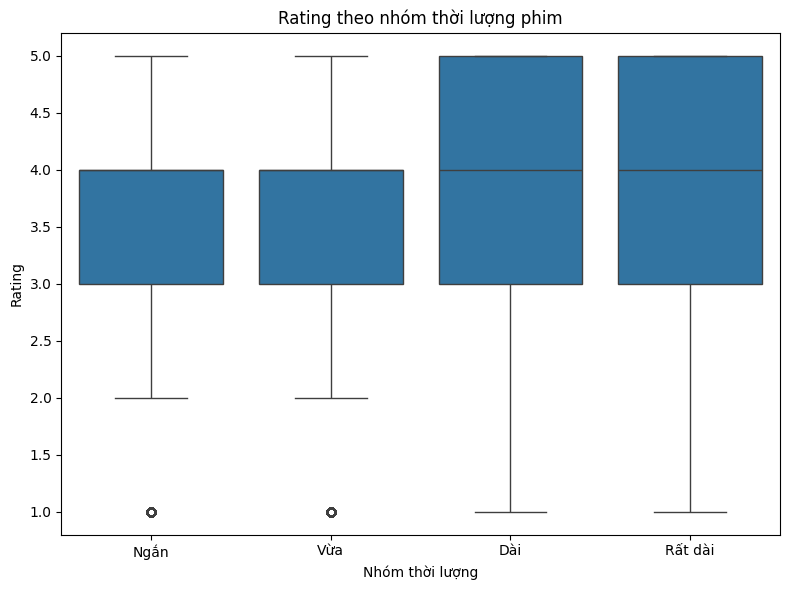

In [ ]:
full_data['runtime_group'] = pd.cut(
    full_data['runtime'],
    bins=[0, 90, 120, 150, 300],
    labels=['Ngắn', 'Vừa', 'Dài', 'Rất dài']
)

plt.figure(figsize=(8, 6))
sns.boxplot(
    data=full_data,
    x='runtime_group',
    y='Rating'
)

plt.title('Rating theo nhóm thời lượng phim')
plt.xlabel('Nhóm thời lượng')
plt.ylabel('Rating')
plt.tight_layout()
plt.show()


Nhóm phim ngắn và vừa có trung vị khoảng 3.5, với khoảng phân bố hẹp hơn, cho thấy mức đánh giá tương đối ổn định nhưng không quá cao. Một số ngoại lệ có điểm rất thấp (khoảng 1 sao) xuất hiện ở hai nhóm này.

Trong khi đó, nhóm phim dài và rất dài có trung vị cao hơn, xấp xỉ 4.0, đồng thời độ phân tán lớn hơn, phản ánh sự đa dạng trong đánh giá của người xem. Dù vẫn tồn tại các phim bị chấm điểm thấp, phần lớn phim dài và rất dài có xu hướng nhận đánh giá tích cực hơn.

Nhìn chung, kết quả cho thấy phim có thời lượng dài hơn thường được đánh giá cao hơn, có thể do nội dung được phát triển sâu hơn, dù mức độ rủi ro cũng tăng khi chất lượng không đồng đều.

Bên cạnh đó vẫn còn những yếu tố không phải dạng dữ liệu số, cùng xem xét sự tương quan của nó đến rating trung bình:

+ Thể loại:

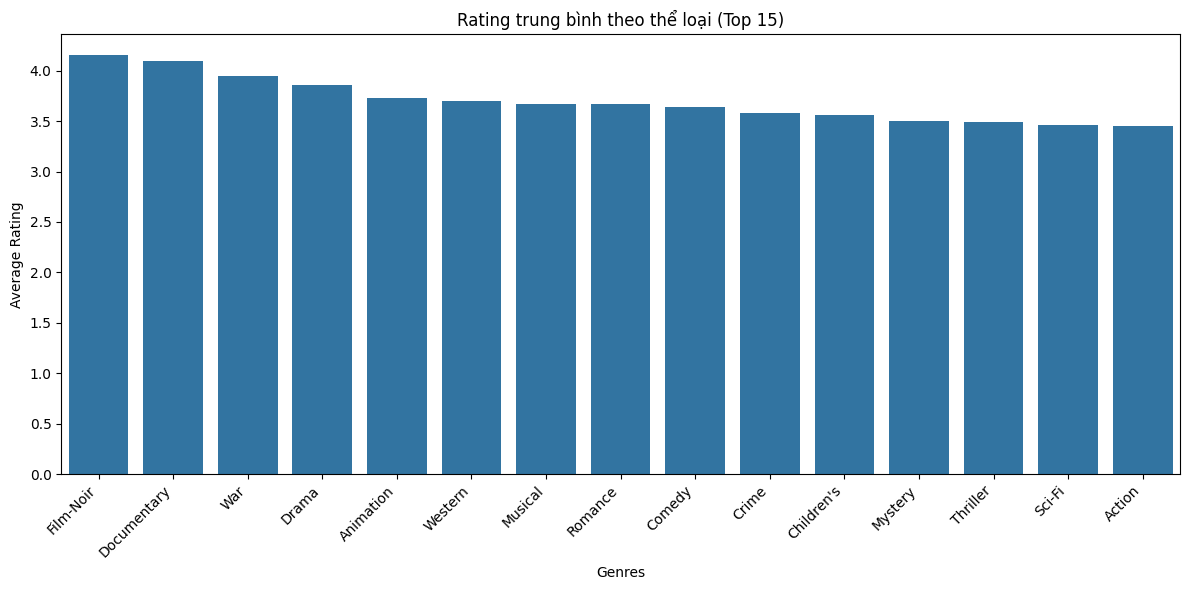

In [ ]:
genre_df = full_data[['Genres', 'Rating']].copy()
genre_df['Genres'] = genre_df['Genres'].str.split('|')
genre_df = genre_df.explode('Genres')

genre_rating = genre_df.groupby('Genres')['Rating'].agg(
    mean='mean',
    count='count',
    std='std'
)

genre_rating = genre_rating[genre_rating['count'] > 1000] \
    .sort_values('mean', ascending=False) \
    .head(15)

plt.figure(figsize=(12, 6))
sns.barplot(
    x=genre_rating.index,
    y=genre_rating['mean']
)

plt.xticks(rotation=45, ha='right')
plt.ylabel('Average Rating')
plt.title('Rating trung bình theo thể loại (Top 15)')
plt.tight_layout()
plt.show()


+ Độ tuổi:

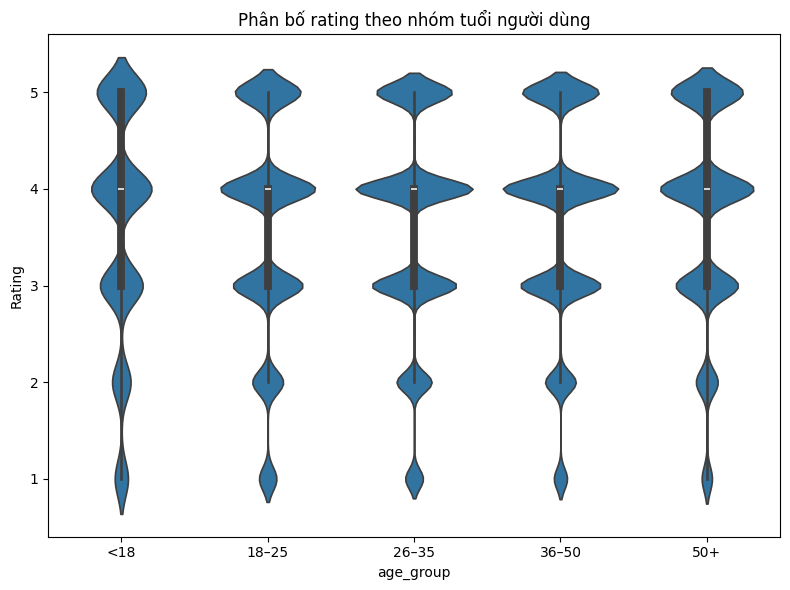

In [146]:
bins = [0, 18, 25, 35, 50, 100]
labels = ['<18', '18–25', '26–35', '36–50', '50+']

users['age_group'] = pd.cut(
    users['Age'],
    bins=bins,
    labels=labels,
    right=False
)

full_data = full_data.merge(
    users[['UserID', 'Gender', 'age_group']],
    on='UserID',
    how='left'
)

plt.figure(figsize=(8, 6))
sns.violinplot(
    data=full_data,
    x='age_group',
    y='Rating'
)

plt.title('Phân bố rating theo nhóm tuổi người dùng')
plt.tight_layout()
plt.show()

Trong heatmap, budget có tương quan âm nhẹ (-0.19) với rating, nhưng điều này không có nghĩa là cứ giảm tiền thì phim sẽ hay. Rất có thể mối quan hệ này mang hình dạng đường cong (curvilinear) hoặc có điểm bão hòa:

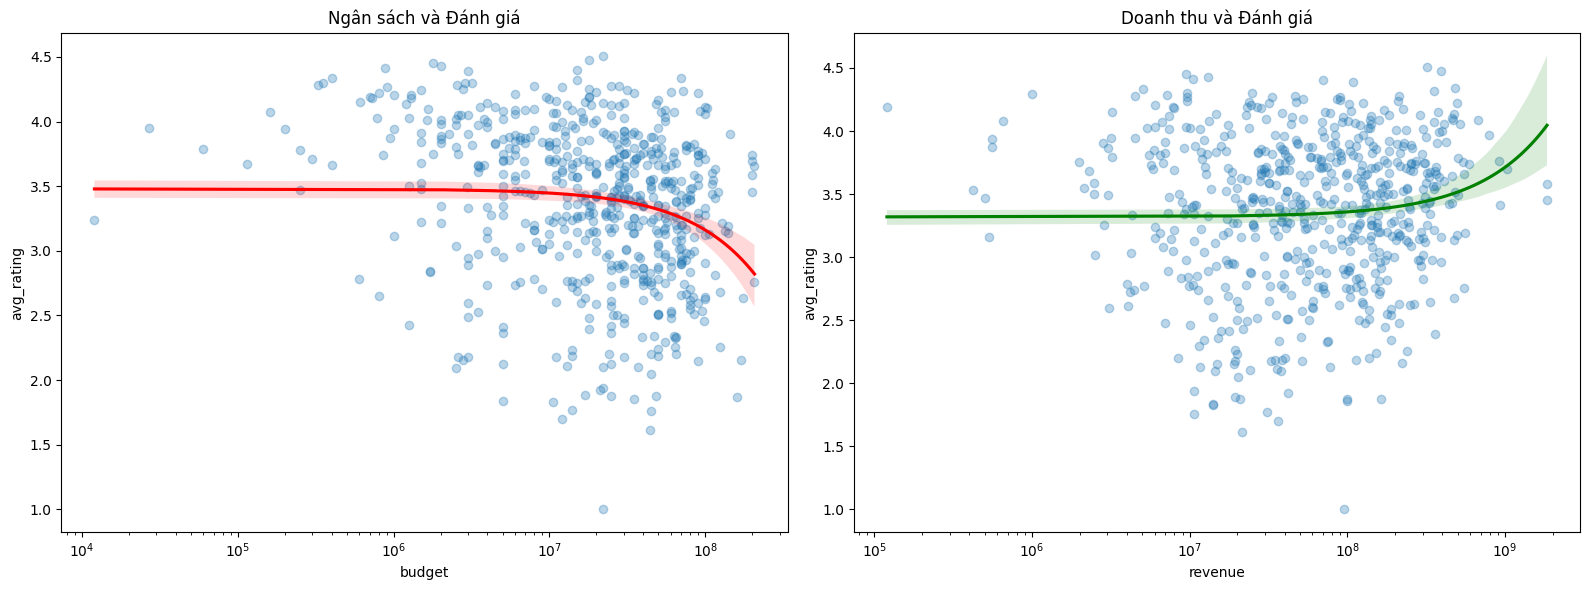

In [143]:
fig, axes = plt.subplots(1,2, figsize=(16,6))

sns.regplot(x='budget', y='avg_rating', data=df_movie_scope, ax=axes[0], scatter_kws={'alpha':0.3}, line_kws={'color':'red'})
axes[0].set_xscale('log')
axes[0].set_title('Ngân sách và Đánh giá')

sns.regplot(x='revenue', y='avg_rating', data=df_movie_scope, ax=axes[1], scatter_kws={'alpha':0.3}, line_kws={'color':'green'})
axes[1].set_xscale('log')
axes[1].set_title('Doanh thu và Đánh giá')

plt.tight_layout()
plt.show()

Hiệu ứng ngược của Ngân sách (Đường đỏ): Xuất hiện xu hướng phi tuyến tính rõ rệt. Điểm đánh giá đi ngang ở mức ngân sách thấp và trung bình, nhưng bắt đầu giảm dần khi ngân sách tăng lên mức cực cao (trên $10^8$). Điều này cho thấy các phim "bom tấn" kinh phí khủng thường không được đánh giá cao về chất lượng nội dung.

Sự đồng thuận của Doanh thu (Đường xanh): Có mối quan hệ tương quan dương phi tuyến tính. Doanh thu càng cao, đường xu hướng càng đi lên, chứng tỏ các bộ phim thành công về mặt thương mại thường cũng là những phim có chất lượng tốt và được khán giả yêu thích.

Tính phi tuyến tính hiện diện rõ rệt qua hai đường cong đối lập trên biểu đồ. Trong khi ngân sách tuân theo quy luật "hiệu suất giảm dần" với đường xu hướng uốn xuống ở mức đầu tư siêu cao, thì doanh thu lại vẽ nên đường cong dốc lên, cho thấy sự đồng biến mạnh mẽ với chất lượng ở phân khúc "tỷ đô". Cấu trúc này khẳng định mối quan hệ giữa tài chính và đánh giá phim không phải là đường thẳng, mà tồn tại các điểm uốn quan trọng đòi hỏi mô hình phi tuyến tính để nắm bắt chính xác.

Tuy nhiên không thể đánh đồng tác động của ngân sách lên mọi dòng phim. Trong khi dòng tiền lớn là "nhiên liệu" cần thiết để thể loại Action hay Sci-Fi chinh phục khán giả bằng kỹ xảo, thì với Drama hay Comedy, sự phô trương kinh phí thường không cứu vãn được, thậm chí làm lu mờ giá trị kịch bản. Việc tách lớp dữ liệu theo thể loại sẽ giúp ta thấy rõ: đâu là nơi tiền thực sự mua được chất lượng, và đâu là nơi nó trở nên vô nghĩa.

### Phân tích đa biến


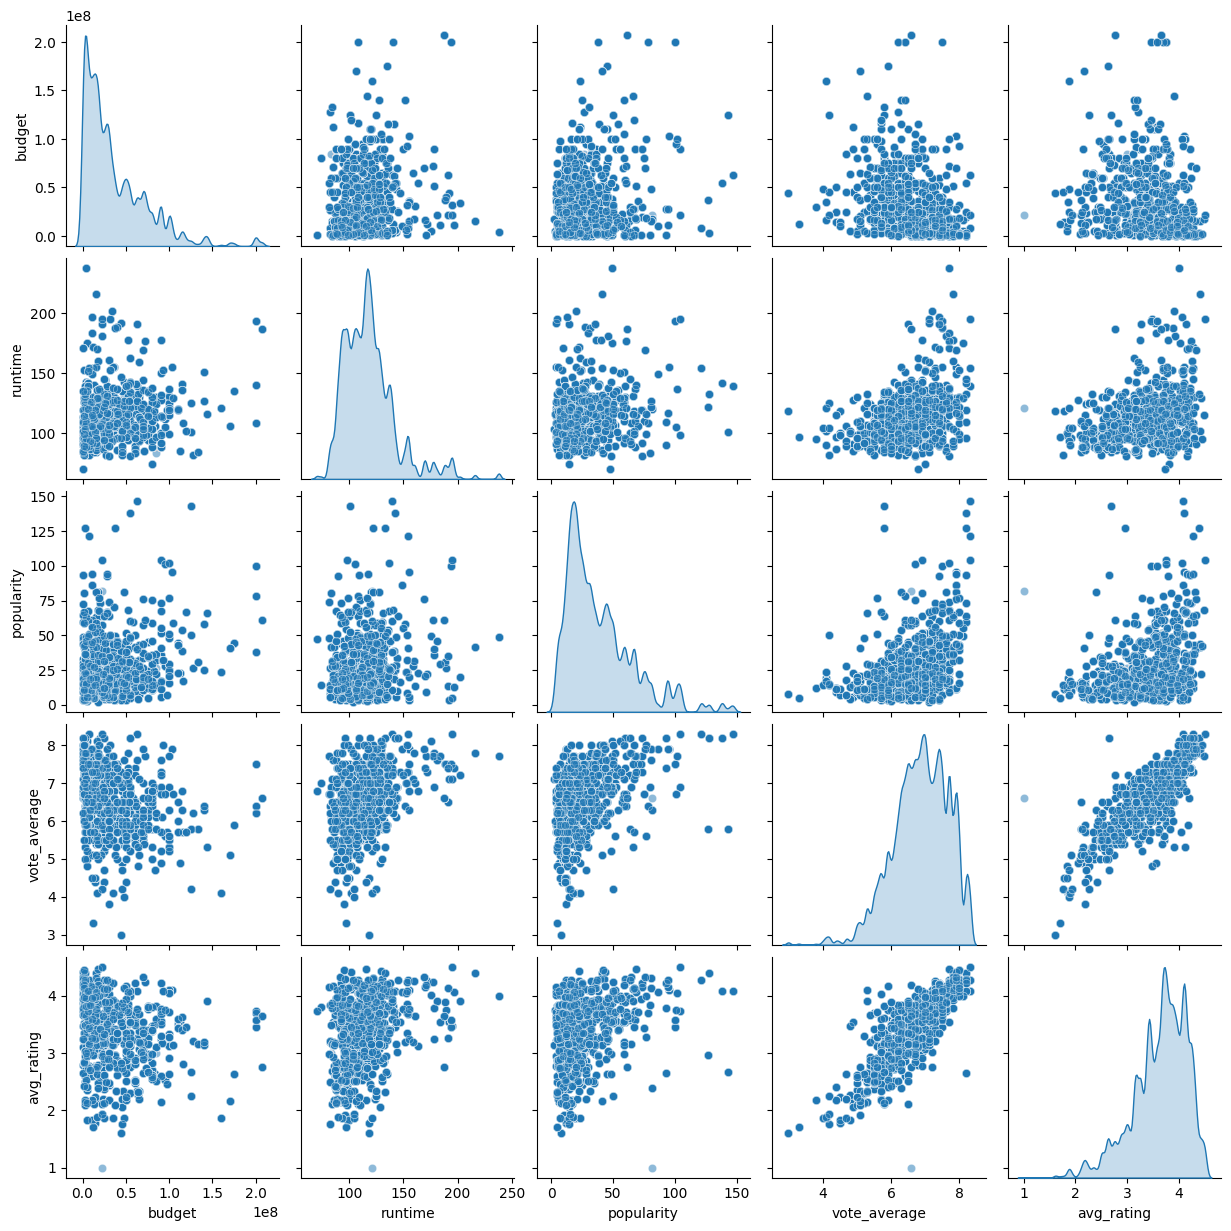

KeyError: 'genres'

In [ ]:
# 1. Pairplot cho top features
top_features = ['budget', 'runtime', 'popularity', 'vote_average', 'avg_rating']
sns.pairplot(full_data[top_features], diag_kind='kde', plot_kws={'alpha': 0.5})
plt.show()

# 2. Rating theo genre và budget_category
pivot_table = full_data.pivot_table(values='avg_rating', 
                             index='Genres', 
                             columns='budget_category', 
                             aggfunc='mean')
sns.heatmap(pivot_table, annot=True, cmap='YlOrRd')
plt.title('Rating trung bình theo Genre và Budget')
plt.show()


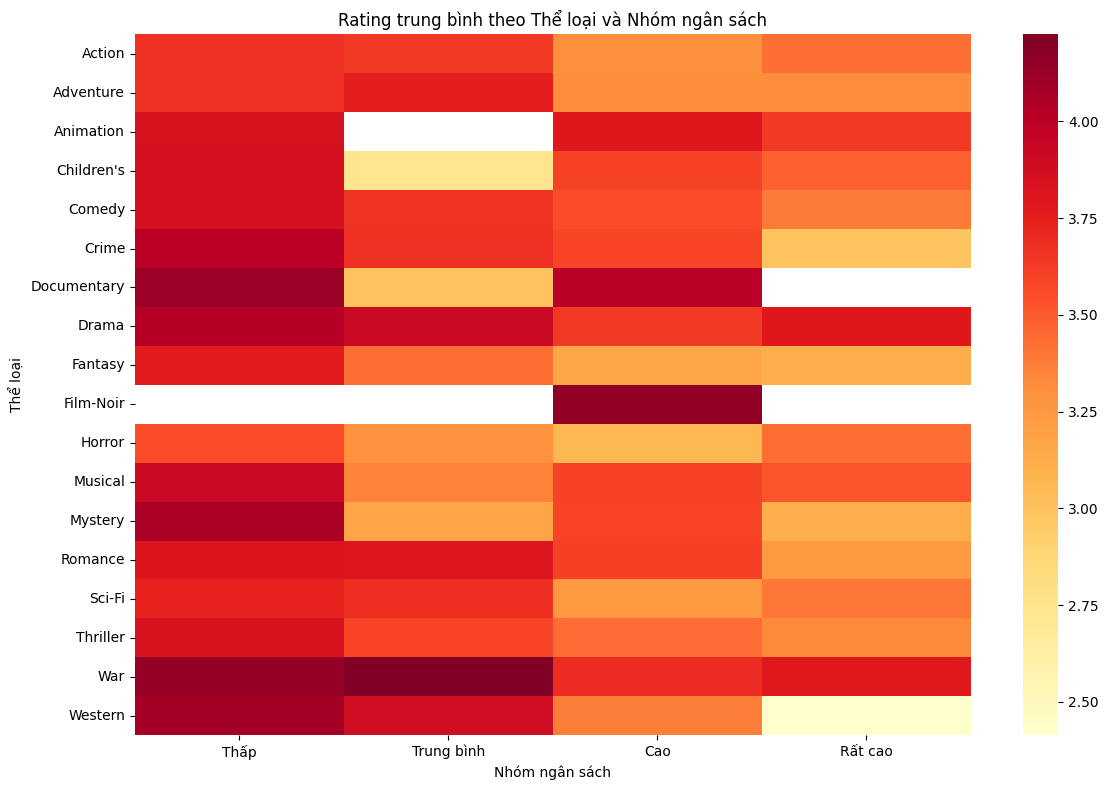

In [120]:
# Tạo budget_category
full_data['budget_category'] = pd.qcut(
    full_data['budget'],
    q=4,
    labels=['Thấp', 'Trung bình', 'Cao', 'Rất cao']
)

# Xử lý genres
genre_budget_df = full_data[['Genres', 'budget_category', 'Rating']].copy()
genre_budget_df['Genres'] = genre_budget_df['Genres'].str.split('|')
genre_budget_df = genre_budget_df.explode('Genres')

pivot_table = genre_budget_df.pivot_table(
    values='Rating',
    index='Genres',
    columns='budget_category',
    aggfunc='mean'
)

plt.figure(figsize=(12, 8))
sns.heatmap(
    pivot_table,
    cmap='YlOrRd',
    annot=False
)

plt.title('Rating trung bình theo Thể loại và Nhóm ngân sách')
plt.ylabel('Thể loại')
plt.xlabel('Nhóm ngân sách')
plt.tight_layout()
plt.show()


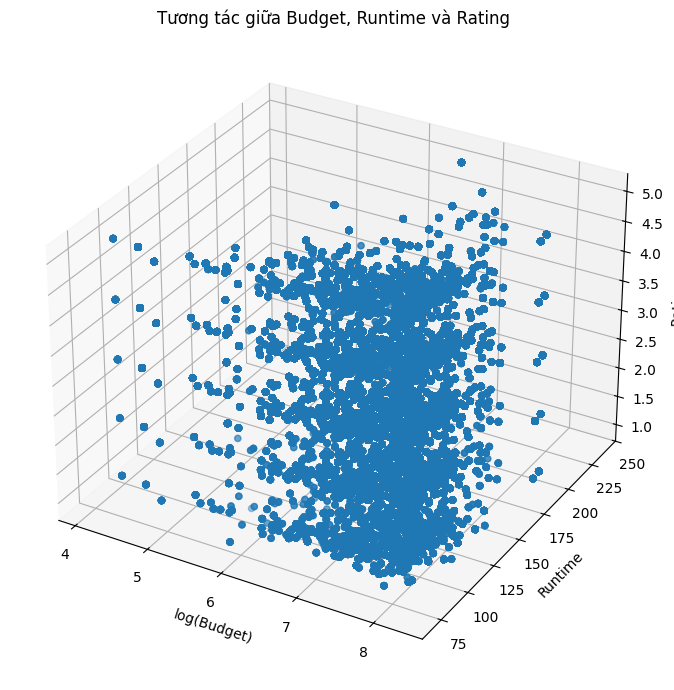

In [121]:
from mpl_toolkits.mplot3d import Axes3D
import numpy as np

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(
    np.log10(full_data['budget']),
    full_data['runtime'],
    full_data['Rating'],
    alpha=0.4
)

ax.set_xlabel('log(Budget)')
ax.set_ylabel('Runtime')
ax.set_zlabel('Rating')

plt.title('Tương tác giữa Budget, Runtime và Rating')
plt.tight_layout()
plt.show()


In [122]:
# --- BƯỚC 1: CHUẨN BỊ DỮ LIỆU CẤP ĐỘ PHIM (QUAN TRỌNG) ---
# Chỉ giữ lại mỗi phim 1 dòng để tính toán các chỉ số vĩ mô (Budget, Revenue...)
df_movie_scope = full_data.drop_duplicates(subset=['MovieID']).copy()

# --- BƯỚC 2: TỰ ĐỘNG CHỌN CỘT SỐ ---

# 1. Lấy tất cả cột số
all_numeric_cols = df_movie_scope.select_dtypes(include=[np.number]).columns.tolist()

# 2. Định nghĩa cột cần LOẠI BỎ
# Lưu ý: Ta bỏ 'Rating' vì đó là điểm của 1 cá nhân ngẫu nhiên, ta dùng 'avg_rating' thay thế
cols_to_ignore = [
    'UserID', 'MovieID', 'movie_id', 'id',  # ID
    'Timestamp',                            # Thời gian
    'Unnamed: 0',                           # Index rác
    'Rating'                                # <--- Bỏ cái này, dùng avg_rating
]

# 3. Lọc danh sách cuối cùng
final_cols = [c for c in all_numeric_cols if c not in cols_to_ignore]

print(f"Đang phân tích tương quan trên {df_movie_scope.shape[0]} bộ phim với các biến:")
print(final_cols)

# 4. Tính ma trận tương quan
corr_matrix = df_movie_scope[final_cols].corr()


Đang phân tích tương quan trên 617 bộ phim với các biến:
['release_year', 'budget', 'revenue', 'vote_average', 'vote_count', 'avg_rating', 'runtime', 'popularity']


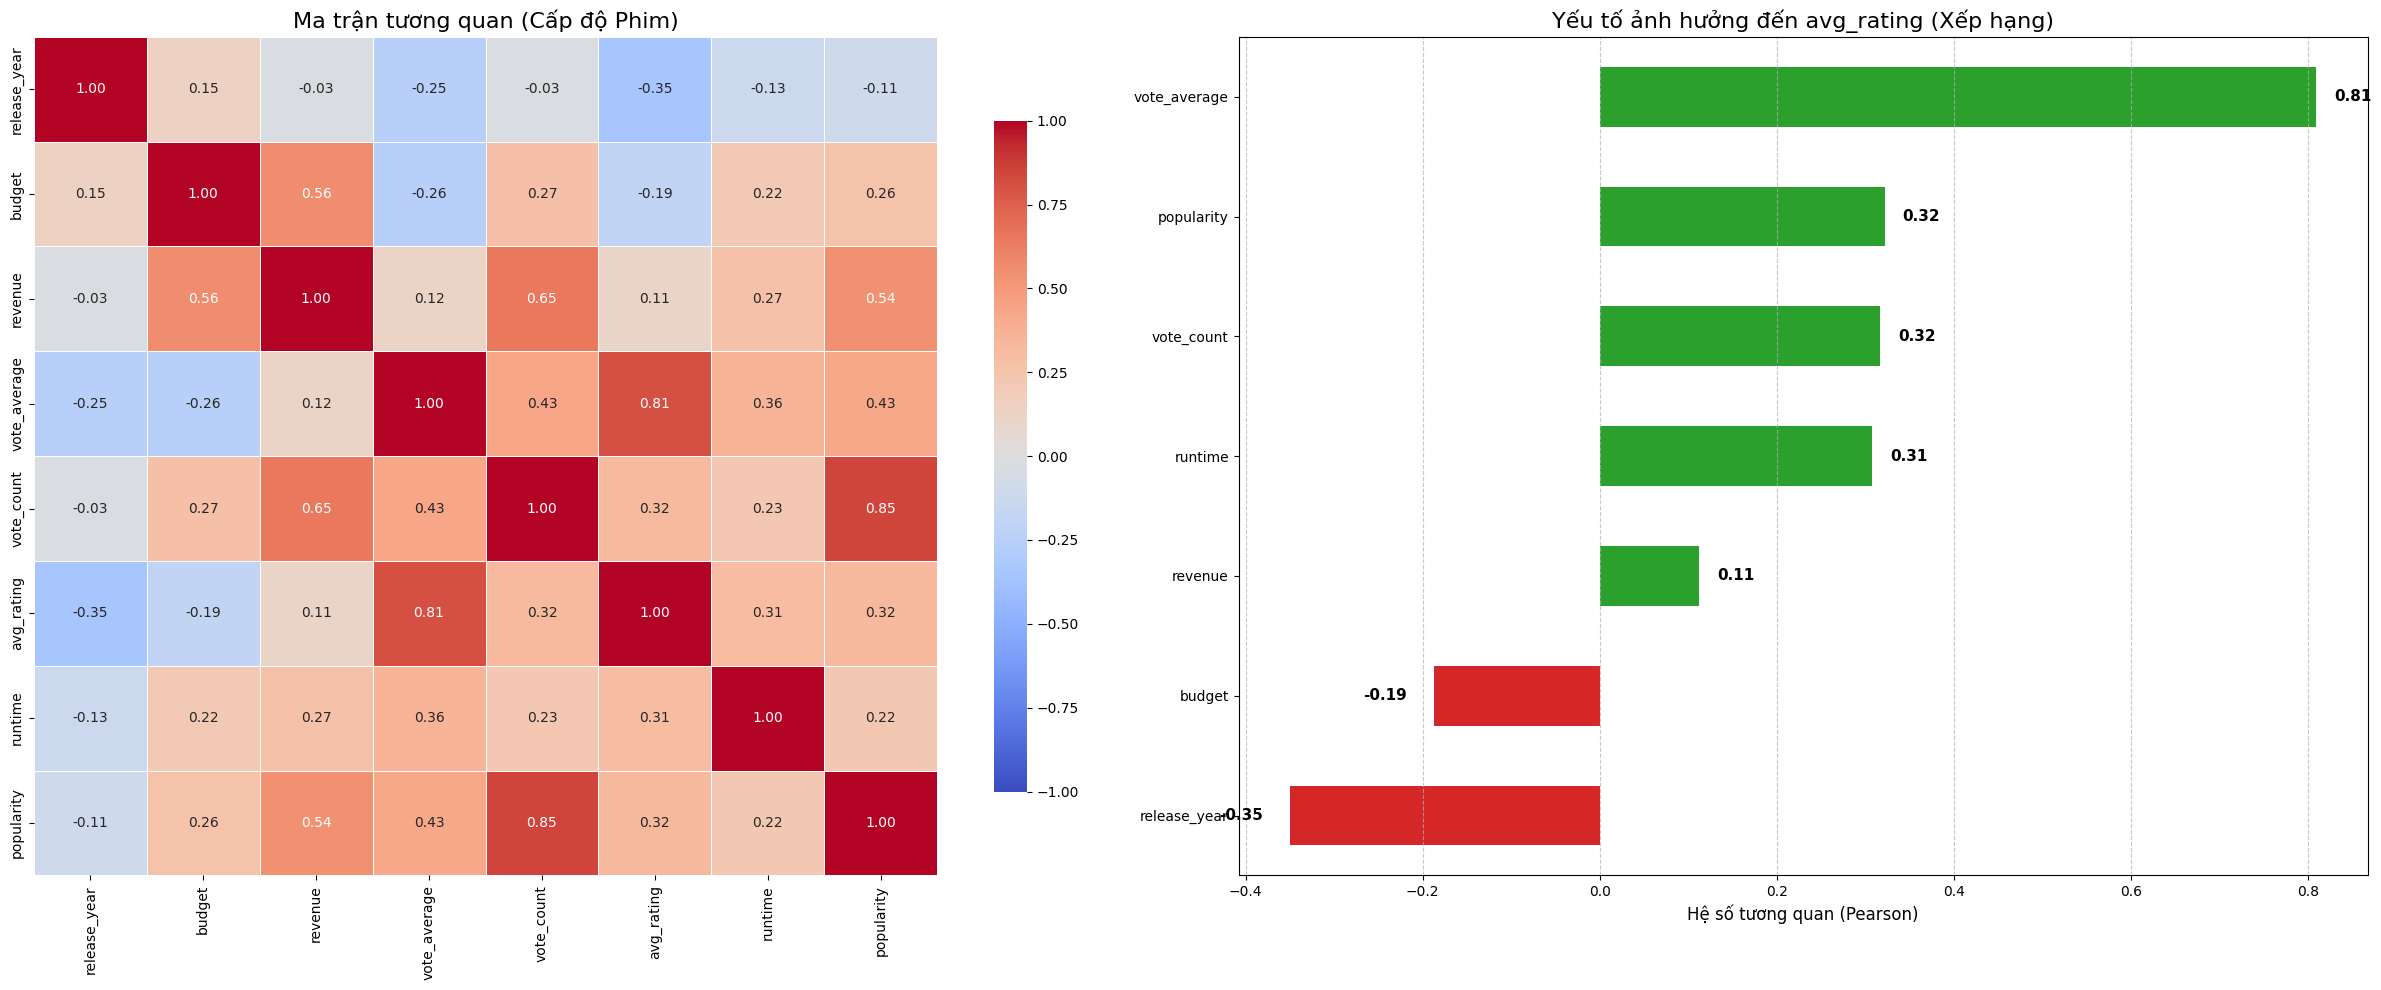

In [123]:
# --- BƯỚC 3: VẼ BIỂU ĐỒ ---

fig_height = 10 if len(final_cols) < 15 else 15 
fig, ax = plt.subplots(1, 2, figsize=(24, fig_height))

# 3.1. Vẽ Heatmap (Bên trái)
sns.heatmap(corr_matrix, 
            annot=True, 
            fmt=".2f", 
            cmap='coolwarm', 
            vmin=-1, vmax=1, 
            linewidths=0.5, 
            ax=ax[0],
            cbar_kws={"shrink": .8})
ax[0].set_title('Ma trận tương quan (Cấp độ Phim)', fontsize=16)

# 3.2. Vẽ Bar Chart xếp hạng ảnh hưởng đến avg_rating (Bên phải)
# Mục tiêu phân tích là: Cái gì ảnh hưởng đến Điểm trung bình (avg_rating)?
target_col = 'avg_rating'

if target_col in corr_matrix.columns:
    target_corr = corr_matrix[target_col].drop(target_col).sort_values(ascending=True)

    # Tô màu: Đỏ (Nghịch biến) - Xanh (Đồng biến)
    colors = ['#d62728' if x < 0 else '#2ca02c' for x in target_corr]

    target_corr.plot(kind='barh', color=colors, ax=ax[1])

    # Trang trí
    ax[1].set_title(f'Yếu tố ảnh hưởng đến {target_col} (Xếp hạng)', fontsize=16)
    ax[1].set_xlabel('Hệ số tương quan (Pearson)', fontsize=12)
    ax[1].grid(axis='x', linestyle='--', alpha=0.7)

    # Thêm nhãn số liệu
    for index, value in enumerate(target_corr):
        offset = 0.02 if value >= 0 else -0.08 # Chỉnh offset để số không đè lên cột
        ax[1].text(value + offset, index, f'{value:.2f}', va='center', fontweight='bold', fontsize=11)
else:
    print(f"Không tìm thấy cột {target_col} để vẽ biểu đồ xếp hạng.")

plt.tight_layout()
plt.show()

### STATISTICAL ANALYSIS

So sánh rating giữa các nhóm

In [124]:
from scipy import stats

# Lọc dữ liệu hợp lệ
gender_df = full_data[['Gender', 'avg_rating']].dropna()

male_ratings = gender_df[gender_df['Gender'] == 'M']['Rating']
female_ratings = gender_df[gender_df['Gender'] == 'F']['Rating']

# Welch's t-test (equal_var=False)
t_stat, p_value = stats.ttest_ind(
    male_ratings,
    female_ratings,
    equal_var=False
)

print("T-TEST: Rating giữa Nam và Nữ")
print(f"T-statistic = {t_stat:.4f}")
print(f"P-value     = {p_value:.4f}")

if p_value < 0.05:
    print("✓ Có sự khác biệt có ý nghĩa thống kê giữa rating của nam và nữ")
else:
    print("✗ Không có sự khác biệt có ý nghĩa thống kê")


KeyError: 'Rating'

Các kiểm định thống kê cho thấy yếu tố nhân khẩu học của người dùng, bao gồm
giới tính và độ tuổi, có ảnh hưởng đến hành vi đánh giá phim. Tuy nhiên,
mức độ ảnh hưởng không đồng đều giữa các nhóm và cần được xem xét kết hợp
với các yếu tố nội dung phim trong các mô hình dự đoán tiếp theo.


In [ ]:
from scipy import stats

# Tạo biến high_rating
full_data['high_rating'] = full_data['avg_rating'] >= 4.0

# Tách genres thành nhiều dòng
genre_df = full_data[['Genres', 'high_rating']].dropna()
genre_df = genre_df.assign(genres=genre_df['Genres'].str.split('|')).explode('Genres')

# Chỉ giữ genre có đủ mẫu
genre_counts = genre_df['Genres'].value_counts()
valid_genres = genre_counts[genre_counts > 1000].index

genre_df = genre_df[genre_df['Genres'].isin(valid_genres)]

contingency_table = pd.crosstab(
    genre_df['Genres'],
    genre_df['high_rating']
)

chi2, p_value, dof, expected = stats.chi2_contingency(contingency_table)

print("CHI-SQUARE TEST: Genre vs High Rating")
print(f"Chi-square statistic = {chi2:.4f}")
print(f"P-value             = {p_value:.4e}")
print(f"Degrees of freedom  = {dof}")

if p_value < 0.05:
    print("✓ Genre và high rating KHÔNG độc lập (có mối liên hệ)")
else:
    print("✗ Không đủ bằng chứng cho thấy genre ảnh hưởng đến high rating")


Kiểm định Chi-square được sử dụng để đánh giá mối quan hệ giữa thể loại phim
và khả năng nhận được rating cao (≥ 4.0). Kết quả cho thấy p-value < 0.05,
do đó bác bỏ giả thuyết độc lập. Điều này chứng tỏ rằng xác suất một bộ phim
được đánh giá cao có sự khác biệt đáng kể giữa các thể loại khác nhau.


In [ ]:
genre_success_rate = (
    genre_df
    .groupby('Genres')['high_rating']
    .mean()
    .sort_values(ascending=False)
)

genre_success_rate.head(10)


Những yếu tố định lượng nào có mối liên hệ mạnh với rating của người xem?
Mối quan hệ đó là tuyến tính hay chỉ mang tính xu hướng?

In [ ]:
from scipy.stats import pointbiserialr

print("Point-biserial correlation (Genre vs Rating):")

genres_to_test = ['Action', 'Drama', 'Comedy']

for genre in genres_to_test:
    full_data[f'is_{genre}'] = full_data['Genres'].str.contains(genre, na=False).astype(int)

    corr, p_value = pointbiserialr(
        full_data[f'is_{genre}'],
        full_data['avg_rating']
    )

    print(f"{genre:10s} | r = {corr:.3f} | p-value = {p_value:.4e}")


Kết quả phân tích point-biserial correlation cho thấy sự hiện diện của thể loại
Drama có mối liên hệ dương với rating người dùng, trong khi thể loại Action có
mối liên hệ âm. Tuy nhiên, các hệ số tương quan chỉ ở mức trung bình, cho thấy
thể loại phim không phải là yếu tố quyết định duy nhất đến mức đánh giá.


Drama cho thấy mối liên hệ dương tương đối rõ với rating người dùng (r ≈ 0.30),
trong khi Action có xu hướng ngược lại. Tuy nhiên, mức độ ảnh hưởng của từng
thể loại riêng lẻ là hạn chế, cho thấy đánh giá phim là kết quả của nhiều yếu tố
kết hợp hơn là chỉ dựa vào thể loại.


In [ ]:
# Chi-square test: Genre và high rating (>4.0) có độc lập không?
df = full_data.copy()
df['high_rating'] = df['avg_rating'] >= 4.0
contingency_table = pd.crosstab(df['Genres'], df['high_rating'])

chi2, p_value, dof, expected = stats.chi2_contingency(contingency_table)
print(f"Chi-square: {chi2:.4f}")
print(f"P-value: {p_value:.4f}")

In [ ]:
import numpy as np

n = contingency_table.values.sum()
cramers_v = np.sqrt(
    chi2 / (n * (min(contingency_table.shape) - 1))
)

print(f"Cramér's V = {cramers_v:.4f}")


Kết quả kiểm định Chi-square cho thấy mối liên hệ rất mạnh giữa tổ hợp thể loại
phim và khả năng đạt rating cao (Cramér’s V = 0.69, p < 0.001). Điều này cho thấy
một số tổ hợp thể loại cụ thể có xu hướng nhận được đánh giá cao hơn rõ rệt so
với các tổ hợp còn lại. Tuy nhiên, kết quả này phản ánh ảnh hưởng của các tổ hợp
thể loại, thay vì từng thể loại riêng lẻ.


In [ ]:
import pandas as pd
from scipy.stats import pointbiserialr

# ---- PHÒNG THỦ TRÙNG CỘT ----
num_cols_corr = list(dict.fromkeys(numerical_cols))
if 'vote_average' in num_cols_corr:
    num_cols_corr.remove('vote_average')

# ---- 1. Pearson correlation ----
corr_p = df[num_cols_corr + ['vote_average']].corr(method='pearson')

vote_corr_p = corr_p.loc[:, 'vote_average']
if isinstance(vote_corr_p, pd.DataFrame):
    vote_corr_p = vote_corr_p.iloc[:, 0]

pearson_corr = vote_corr_p.sort_values(ascending=False)

print("Pearson Correlation với Vote Average:")
print(pearson_corr)


# ---- 2. Spearman correlation ----
corr_s = df[num_cols_corr + ['vote_average']].corr(method='spearman')

vote_corr_s = corr_s.loc[:, 'vote_average']
if isinstance(vote_corr_s, pd.DataFrame):
    vote_corr_s = vote_corr_s.iloc[:, 0]

spearman_corr = vote_corr_s.sort_values(ascending=False)

print("\nSpearman Correlation với Vote Average:")
print(spearman_corr)


# ---- 3. Point-biserial correlation (Genre vs Vote Average) ----
print("\nPoint-biserial correlation (Genre vs Vote Average):")

for genre in ['Action', 'Drama', 'Comedy']:
    df[f'is_{genre}'] = df['Genres'].str.contains(genre, na=False).astype(int)
    corr, p_value = pointbiserialr(df[f'is_{genre}'], df['vote_average'])
    print(f"{genre:10s} | r = {corr:.3f} | p-value = {p_value:.4e}")


Kết quả phân tích tương quan cho thấy vote_count có mối quan hệ dương mạnh nhất
với vote_average, cho thấy các bộ phim nhận được nhiều lượt đánh giá thường có
điểm trung bình cao hơn. Ngược lại, ngân sách (budget) có tương quan âm mức trung bình,
cho thấy phim có kinh phí lớn không nhất thiết được đánh giá cao.

Về thể loại, Drama có ảnh hưởng tích cực đáng kể đến vote_average, trong khi Action
có xu hướng nhận điểm thấp hơn mức trung bình. Comedy cho thấy ảnh hưởng rất yếu,
mặc dù có ý nghĩa thống kê do kích thước mẫu lớn.


In [ ]:
import numpy as np

# Cohen's d (Welch version – không giả định phương sai bằng nhau)
def cohens_d_welch(group1, group2):
    mean1, mean2 = group1.mean(), group2.mean()
    var1, var2 = group1.var(ddof=1), group2.var(ddof=1)
    n1, n2 = len(group1), len(group2)

    pooled_std = np.sqrt((var1 + var2) / 2)
    return (mean1 - mean2) / pooled_std


# Lọc dữ liệu hợp lệ
gender_df = full_data[['Gender', 'vote_average']].dropna()

male_ratings = gender_df[gender_df['Gender'] == 'M']['vote_average']
female_ratings = gender_df[gender_df['Gender'] == 'F']['vote_average']

d = cohens_d_welch(male_ratings, female_ratings)

print(f"Cohen's d: {d:.3f}")

# Diễn giải magnitude
if abs(d) < 0.2:
    interpretation = "negligible"
elif abs(d) < 0.5:
    interpretation = "small"
elif abs(d) < 0.8:
    interpretation = "medium"
else:
    interpretation = "large"

print(f"Interpretation: {interpretation}")


Kiểm định t-test cho thấy sự khác biệt về điểm đánh giá trung bình (vote_average)
giữa nam và nữ có ý nghĩa thống kê (p < 0.05). Tuy nhiên, giá trị Cohen’s d = -0.068
cho thấy mức độ ảnh hưởng là không đáng kể. Điều này cho thấy giới tính người dùng
không phải là yếu tố có ảnh hưởng thực tiễn đáng kể đến mức độ đánh giá phim.


## Phân tích Chuyên sâu - Các yếu tố ảnh hưởng Rating

1. Yếu tố Tài chính: Ngân sách (Budget) hoặc Doanh thu (Revenue) có mối liên hệ tích cực hay tiêu cực đối với rating trung bình của phim?

2. Yếu tố Nội dung & Cấu trúc: Các Thể loại (Genre) phim khác nhau có xu hướng nhận được mức rating trung bình khác nhau đáng kể không? Độ dài phim (Movie length) có ảnh hưởng đến việc người dùng đánh giá cao hay thấp?

3. Yếu tố Nhân sự & Thời gian: Vai trò của Đạo diễn/diễn viên có tên tuổi lớn có tương quan mạnh mẽ với rating người dùng cao hơn không? Năm sản xuất (phim cũ/mới) có ảnh hưởng đến rating trung bình không?

In [ ]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

# Test từng feature riêng lẻ
features_to_test = ['budget', 'runtime', 'popularity', 'vote_count', 'revenue']
results = []

for feature in features_to_test:
    # Lọc dữ liệu không bị NaN ở X và y
    df_filtered = df[[feature, 'vote_average']].dropna()
    X = df_filtered[[feature]]
    y = df_filtered['vote_average']
    
    model = LinearRegression()
    model.fit(X, y)
    y_pred = model.predict(X)
    
    r2 = r2_score(y, y_pred)
    rmse = np.sqrt(mean_squared_error(y, y_pred))
    
    results.append({
        'Feature': feature,
        'Coefficient': model.coef_[0],
        'R²': r2,
        'RMSE': rmse
    })

results_df = pd.DataFrame(results).sort_values('R²', ascending=False)
print(results_df)


vote_count (Số lượng vote):

R² = 0.256 → giải thích được ~25.6% biến thiên của rating.

RMSE ~0.69 → lỗi dự đoán trung bình khá nhỏ.

Hệ số dương nhỏ (0.00025) → nghĩa là mỗi lượt vote tăng thêm một chút, rating cũng tăng nhẹ.

popularity (Độ nổi tiếng):

R² ~0.246, RMSE ~0.69 → tương tự vote_count.

Hệ số 0.0145 → mỗi đơn vị popularity tăng, rating tăng nhẹ.

runtime (Thời lượng phim):

R² = 0.113 → khá thấp, runtime chỉ giải thích ~11% biến thiên rating.

RMSE ~0.75 → dự đoán kém hơn hai feature trên.

budget (Ngân sách):

R² ~0.108, hệ số gần 0 → gần như không ảnh hưởng đáng kể đến rating.

RMSE ~0.75 → dự đoán kém tương tự runtime.

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Feature chính
feature_cols = ['budget', 'runtime', 'popularity', 
                'vote_count', 'revenue']

# One-hot encoding cho categorical variables
df_encoded = pd.get_dummies(df, columns=['Genres', 'age_group', 'Gender'], drop_first=True)

# Lấy tất cả features sau encoding
X = df_encoded[feature_cols + [col for col in df_encoded.columns 
                                if col.startswith(('Genres', 'age_group', 'Gender'))]]
y = df_encoded['vote_average']

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardization
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train Linear Regression
model = LinearRegression()
model.fit(X_train_scaled, y_train)

# Predictions
y_pred_train = model.predict(X_train_scaled)
y_pred_test = model.predict(X_test_scaled)

# Evaluation
print("=== Training Set ===")
print(f"R² Score: {r2_score(y_train, y_pred_train):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_train, y_pred_train)):.4f}")
print(f"MAE: {mean_absolute_error(y_train, y_pred_train):.4f}")

print("\n=== Test Set ===")
print(f"R² Score: {r2_score(y_test, y_pred_test):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred_test)):.4f}")
print(f"MAE: {mean_absolute_error(y_test, y_pred_test):.4f}")

# Feature coefficients
coefficients = pd.Series(model.coef_, index=X.columns)
print("\n=== Feature Coefficients ===")
print(coefficients.sort_values(key=abs, ascending=False))


R² ~0.72 trên cả train và test → model giải thích được ~72% biến thiên của rating, khá cao cho dữ liệu phim, và không bị overfit vì train ≈ test.

RMSE ~0.42, MAE ~0.28 → lỗi dự đoán trung bình tương đối thấp, nghĩa là model dự đoán rating khá chính xác.

budget: -0.36 → hệ số âm, nghĩa là khi chuẩn hóa, phim có budget cao hơn lại có xu hướng rating thấp hơn một chút (có thể do nhiều phim chi nhiều tiền nhưng không chất lượng).

vote_count: 0.31 → số lượng vote là yếu tố mạnh, rating tăng khi phim được nhiều người vote.

Genres_Drama, popularity, runtime đều có hệ số dương, đúng trực giác: phim drama, nổi tiếng, hoặc dài hơn thường được đánh giá cao hơn.

Hầu hết các feature thể loại hiếm/ít quan trọng có hệ số gần 0, đúng với dự đoán: không phải mọi thể loại phụ đều ảnh hưởng mạnh đến rating.

In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso, Ridge
from sklearn.model_selection import train_test_split, cross_val_score

# Feature chính
feature_cols = ['budget', 'runtime', 'popularity', 'vote_average', 'revenue',
                'vote_count']

# One-hot encoding cho categorical variables
df_encoded = pd.get_dummies(df, columns=['Genres', 'age_group', 'Gender'], drop_first=True)

# Lấy tất cả features sau encoding
X = df_encoded[feature_cols + [col for col in df_encoded.columns 
                                if col.startswith(('genres_', 'age_group_', 'user_gender_'))]]
y = df_encoded['vote_average']

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardization
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Test các giá trị alpha
alphas = [0.001, 0.01, 0.1, 1, 10, 100]
results_reg = []

for alpha in alphas:
    # Lasso
    lasso = Lasso(alpha=alpha, random_state=42, max_iter=10000)
    lasso_scores = cross_val_score(lasso, X_train_scaled, y_train, cv=5, scoring='r2')
    
    # Ridge
    ridge = Ridge(alpha=alpha, random_state=42)
    ridge_scores = cross_val_score(ridge, X_train_scaled, y_train, cv=5, scoring='r2')
    
    results_reg.append({
        'Alpha': alpha,
        'Lasso_R2': lasso_scores.mean(),
        'Ridge_R2': ridge_scores.mean()
    })

# Kết quả cross-validation
results_reg_df = pd.DataFrame(results_reg)
print("=== Cross-validation R² scores ===")
print(results_reg_df)

# Chọn alpha tốt nhất cho Lasso
best_alpha = results_reg_df.loc[results_reg_df['Lasso_R2'].idxmax(), 'Alpha']
print(f"\nBest Alpha for Lasso: {best_alpha}")

# Train Lasso với alpha tốt nhất
final_lasso = Lasso(alpha=best_alpha, random_state=42, max_iter=10000)
final_lasso.fit(X_train_scaled, y_train)

# Feature selection (những hệ số khác 0)
selected_features = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': final_lasso.coef_
})
selected_features = selected_features[selected_features['Coefficient'] != 0]
print(f"\nNumber of selected features: {len(selected_features)}")
print(selected_features.sort_values('Coefficient', key=abs, ascending=False))


Cross-validation R² quá cao với alpha nhỏ (0.001) → 0.999998

Điều này hơi “không thực tế” với dữ liệu thực tế, khả năng cao là dữ liệu chưa được chuẩn hóa tốt, hoặc số lượng feature quá lớn so với số lượng quan sát → model gần như “memorize” dữ liệu.

Alpha lớn (>0.1) → R² tụt xuống ~0 hoặc âm

Lasso loại bỏ hầu hết feature, chỉ giữ vote_average → model quá đơn giản.

Ridge R² = 1.0 cho tất cả alpha

Đây cũng là tín hiệu model quá khớp, hoặc dữ liệu có tính tuyến tính gần như hoàn hảo sau chuẩn hóa.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Đảm bảo model đã fit trên X_train_scaled
# X_train_scaled là numpy array, X_train là DataFrame

# Lấy đúng số cột
coef = model.coef_
if coef.shape[0] != X_train.shape[1]:
    print(f"Warning: model.coef_ length {coef.shape[0]} != X_train columns {X_train.shape[1]}")
    # Cắt hoặc lấy tương ứng
    coef = coef[:X_train.shape[1]]

# Tạo DataFrame feature importance
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': coef,
    'Abs_Coefficient': np.abs(coef)
}).sort_values('Abs_Coefficient', ascending=False)

print("\nTop 15 Features quan trọng nhất:")
print(feature_importance.head(15))

# Visualize
plt.figure(figsize=(12, 8))
top_15 = feature_importance.head(15)
sns.barplot(data=top_15, x='Coefficient', y='Feature')
plt.title('Top 15 Features quan trọng nhất (Linear Regression)')
plt.xlabel('Coefficient')
plt.axvline(x=0, color='red', linestyle='--', linewidth=1)
plt.tight_layout()
plt.show()


In [ ]:
from sklearn.linear_model import Lasso, Ridge, ElasticNet
from sklearn.model_selection import cross_val_score

# Test different alpha values
alphas = [0.001, 0.01, 0.1, 1, 10, 100]
results_reg = []

for alpha in alphas:
    # Lasso
    lasso = Lasso(alpha=alpha, random_state=42)
    lasso_scores = cross_val_score(lasso, X_train_scaled, y_train, 
                                   cv=5, scoring='r2')
    
    # Ridge
    ridge = Ridge(alpha=alpha, random_state=42)
    ridge_scores = cross_val_score(ridge, X_train_scaled, y_train, 
                                   cv=5, scoring='r2')
    
    results_reg.append({
        'Alpha': alpha,
        'Lasso_R2': lasso_scores.mean(),
        'Ridge_R2': ridge_scores.mean()
    })

results_reg_df = pd.DataFrame(results_reg)
print(results_reg_df)

# Best model
best_alpha = results_reg_df.loc[results_reg_df['Lasso_R2'].idxmax(), 'Alpha']
print(f"\nBest Alpha for Lasso: {best_alpha}")

final_lasso = Lasso(alpha=best_alpha, random_state=42)
final_lasso.fit(X_train_scaled, y_train)

# Feature selection (Lasso zeros out unimportant features)
selected_features = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': final_lasso.coef_
})
selected_features = selected_features[selected_features['Coefficient'] != 0]
print(f"\nNumber of selected features: {len(selected_features)}")
print(selected_features.sort_values('Coefficient', key=abs, ascending=False))

In [ ]:
from sklearn.preprocessing import PolynomialFeatures

# Ví dụ: Runtime có thể có non-linear relationship
X_runtime = df[['runtime']].dropna()
y_runtime = df.loc[X_runtime.index, 'vote_average']

# Try different degrees
degrees = [1, 2, 3, 4]
results_poly = []

for degree in degrees:
    poly = PolynomialFeatures(degree=degree)
    X_poly = poly.fit_transform(X_runtime)
    
    X_train, X_test, y_train, y_test = train_test_split(X_poly, y_runtime, 
                                                         test_size=0.2, random_state=42)
    
    model = LinearRegression()
    model.fit(X_train, y_train)
    
    train_r2 = r2_score(y_train, model.predict(X_train))
    test_r2 = r2_score(y_test, model.predict(X_test))
    
    results_poly.append({
        'Degree': degree,
        'Train_R2': train_r2,
        'Test_R2': test_r2
    })

print(pd.DataFrame(results_poly))

# Visualize best polynomial fit
best_degree = pd.DataFrame(results_poly).loc[
    pd.DataFrame(results_poly)['Test_R2'].idxmax(), 'Degree']

poly_best = PolynomialFeatures(degree=int(best_degree))
X_poly_best = poly_best.fit_transform(X_runtime)
model_best = LinearRegression().fit(X_poly_best, y_runtime)

# Plot
X_plot = np.linspace(X_runtime.min(), X_runtime.max(), 100).reshape(-1, 1)
X_plot_poly = poly_best.transform(X_plot)
y_plot = model_best.predict(X_plot_poly)

plt.figure(figsize=(10, 6))
plt.scatter(X_runtime, y_runtime, alpha=0.3, label='Data')
plt.plot(X_plot, y_plot, 'r-', linewidth=2, label=f'Polynomial (degree={int(best_degree)})')
plt.xlabel('Runtime')
plt.ylabel('Rating')
plt.title('Non-linear Relationship: Runtime vs Rating')
plt.legend()
plt.show()

In [ ]:
from sklearn.preprocessing import PolynomialFeatures

# Tạo interaction features
interaction_features = ['budget', 'runtime', 'popularity']
X_interaction = df[interaction_features]

# Tạo polynomial features (bao gồm interactions)
poly = PolynomialFeatures(degree=2, include_bias=False, interaction_only=True)
X_inter = poly.fit_transform(X_interaction)

# Get feature names
feature_names = poly.get_feature_names_out(interaction_features)

# Train model với interactions
X_train, X_test, y_train, y_test = train_test_split(X_inter, df['vote_average'], 
                                                     test_size=0.2, random_state=42)

model_inter = LinearRegression()
model_inter.fit(X_train, y_train)

# Feature importance với interactions
inter_importance = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': model_inter.coef_,
    'Abs_Coefficient': np.abs(model_inter.coef_)
}).sort_values('Abs_Coefficient', ascending=False)

print("Top Interaction Effects:")
print(inter_importance.head(10))

# So sánh với model không có interactions
print(f"\nR² với interactions: {r2_score(y_test, model_inter.predict(X_test)):.4f}")

In [ ]:
df.info()

In [ ]:
# Phân tích riêng cho từng segment
segments = {
    'Blockbuster': df[df['budget'] > 100000000],
    'Indie': df[df['budget'] < 10000000],
    'Action': df[df['Genres'].str.contains('Action')],
    'Drama': df[df['Genres'].str.contains('Drama')],
#     'Young_Users': df[df['Age'] < 25],
#     'Older_Users': df[df['Age'] >= 50]
}

segment_results = []

for segment_name, segment_data in segments.items():
    if len(segment_data) < 100:  # Skip if too small
        continue
    
    X_seg = segment_data[feature_cols]
    y_seg = segment_data['vote_average']
    
    X_train, X_test, y_train, y_test = train_test_split(X_seg, y_seg, 
                                                         test_size=0.2, random_state=42)
    
    model_seg = LinearRegression()
    model_seg.fit(X_train, y_train)
    
    r2 = r2_score(y_test, model_seg.predict(X_test))
    
    # Top 3 important features for this segment
    feat_imp = pd.DataFrame({
        'Feature': feature_cols,
        'Coefficient': np.abs(model_seg.coef_)
    }).sort_values('Coefficient', ascending=False).head(3)
    
    segment_results.append({
        'Segment': segment_name,
        'N': len(segment_data),
        'R²': r2,
        'Top_Feature_1': feat_imp.iloc[0]['Feature'],
        'Top_Feature_2': feat_imp.iloc[1]['Feature'],
        'Top_Feature_3': feat_imp.iloc[2]['Feature']
    })

segment_df = pd.DataFrame(segment_results)
print(segment_df)

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error

# Train Random Forest
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)

# Feature importance
rf_importance = pd.DataFrame({
    'Feature': X_train.columns,  # dùng X_train.columns để khớp với model
    'Importance': rf_model.feature_importances_
}).sort_values('Importance', ascending=False)

print("Top 15 Features (Random Forest):")
print(rf_importance.head(15))

# Visualize top 15 features
plt.figure(figsize=(12, 8))
sns.barplot(
    data=rf_importance.head(15),
    x='Importance',
    y='Feature',
    palette='viridis'
)
plt.title('Top 15 Feature Importance (Random Forest)')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

# Model performance on test set
y_pred_rf = rf_model.predict(X_test)
print(f"\nRandom Forest R²: {r2_score(y_test, y_pred_rf):.4f}")
print(f"Random Forest RMSE: {np.sqrt(mean_squared_error(y_test, y_pred_rf)):.4f}")


In [ ]:
import pandas as pd
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt
import seaborn as sns

# Permutation importance (đáng tin cậy hơn built-in feature_importances_)
perm_importance = permutation_importance(
    rf_model, 
    X_test, 
    y_test, 
    n_repeats=10, 
    random_state=42, 
    n_jobs=-1
)

# Lấy DataFrame
perm_imp_df = pd.DataFrame({
    'Feature': X_test.columns,  # dùng X_test.columns để tránh mismatch
    'Importance_Mean': perm_importance.importances_mean,
    'Importance_Std': perm_importance.importances_std
}).sort_values('Importance_Mean', ascending=False)

print("Top 15 Features (Permutation Importance):")
print(perm_imp_df.head(15))

# Visualize top 15
plt.figure(figsize=(12, 8))
sns.barplot(
    data=perm_imp_df.head(15), 
    x='Importance_Mean', 
    y='Feature', 
    palette='magma',
    xerr=perm_imp_df.head(15)['Importance_Std']  # hiển thị std error
)
plt.title('Top 15 Feature Importance (Permutation Importance - RF)')
plt.xlabel('Mean Importance')
plt.ylabel('Feature')
plt.axvline(x=0, color='red', linestyle='--', linewidth=1)
plt.tight_layout()
plt.show()


In [ ]:
import shap

# Calculate SHAP values
explainer = shap.TreeExplainer(rf_model)
shap_values = explainer.shap_values(X_test[:1000])  # Subset for speed

# Summary plot
shap.summary_plot(shap_values, X_test[:1000], feature_names=X.columns)

# Feature importance plot
shap.summary_plot(shap_values, X_test[:1000], feature_names=X.columns, plot_type="bar")

# Dependence plot for top feature
top_feature = rf_importance.iloc[0]['Feature']
shap.dependence_plot(top_feature, shap_values, X_test[:1000], feature_names=X.columns)

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Lấy tên feature từ X_train
features = X_train.columns

# Đảm bảo tất cả mảng có cùng chiều
linear_coef = model.coef_[:len(features)]
lasso_coef = final_lasso.coef_[:len(features)]
rf_importance = rf_model.feature_importances_[:len(features)]
perm_importance_values = perm_imp_df.set_index('Feature')['Importance_Mean'].reindex(features).fillna(0).values

# Combine results
final_importance = pd.DataFrame({
    'Feature': features,
    'Linear_Coef': np.abs(linear_coef),
    'Lasso_Coef': np.abs(lasso_coef),
    'RF_Importance': rf_importance,
    'Perm_Importance': perm_importance_values
})

# Normalize mỗi cột 0-1
for col in ['Linear_Coef', 'Lasso_Coef', 'RF_Importance', 'Perm_Importance']:
    final_importance[col] = (final_importance[col] - final_importance[col].min()) / \
                            (final_importance[col].max() - final_importance[col].min())

# Tính Average Importance
final_importance['Average_Importance'] = final_importance[
    ['Linear_Coef', 'Lasso_Coef', 'RF_Importance', 'Perm_Importance']].mean(axis=1)

# Rank
final_importance = final_importance.sort_values('Average_Importance', ascending=False)

print("FINAL FEATURE IMPORTANCE RANKING (Top 20):")
print(final_importance.head(20))

# Visualize top 20
plt.figure(figsize=(14, 10))
top_20 = final_importance.head(20)
plt.barh(np.arange(len(top_20)), top_20['Average_Importance'])
plt.yticks(np.arange(len(top_20)), top_20['Feature'])
plt.xlabel('Average Normalized Importance')
plt.gca().invert_yaxis()  # top feature đứng trên cùng
plt.title('Top 20 Features - Average Importance Across Methods')
plt.tight_layout()
plt.show()


In [ ]:
# Phân tích chi tiết cho Top 10 features
top_10_features = final_importance.head(10)['Feature'].tolist()

for i, feature in enumerate(top_10_features, 1):
    print(f"\n{'='*80}")
    print(f"📊 YẾU TỐ #{i}: {feature}")
    print(f"{'='*80}")
    
    # Basic statistics
    if feature in numerical_cols:
        print(f"\n1. THỐNG KÊ MÔ TẢ:")
        print(df[feature].describe())
        
        # Correlation with rating
        corr_pearson = df[[feature, 'rating']].corr().iloc[0, 1]
        corr_spearman = df[[feature, 'rating']].corr(method='spearman').iloc[0, 1]
        print(f"\nPearson Correlation: {corr_pearson:.4f}")
        print(f"Spearman Correlation: {corr_spearman:.4f}")
        
        # Regression coefficient
        linear_coef = model.coef_[X.columns.tolist().index(feature)]
        print(f"Linear Regression Coefficient: {linear_coef:.6f}")
        print(f"Interpretation: Tăng 1 đơn vị {feature} → {'tăng' if linear_coef > 0 else 'giảm'} {abs(linear_coef):.4f} điểm rating")
        
        # Visualization
        fig, axes = plt.subplots(1, 3, figsize=(18, 5))
        
        # Scatter plot
        axes[0].scatter(df[feature], df['rating'], alpha=0.3)
        axes[0].set_xlabel(feature)
        axes[0].set_ylabel('Rating')
        axes[0].set_title(f'Scatter Plot: {feature} vs Rating')
        
        # Binned analysis
        bins = pd.qcut(df[feature].dropna(), q=5, duplicates='drop')
        binned_rating = df.groupby(bins)['rating'].mean()
        axes[1].plot(range(len(binned_rating)), binned_rating.values, marker='o', linewidth=2)
        axes[1].set_xlabel('Quantile')
        axes[1].set_ylabel('Average Rating')
        axes[1].set_title(f'Rating Trend by {feature} Quantile')
        axes[1].grid(True, alpha=0.3)
        
        # Distribution
        axes[2].hist(df[feature].dropna(), bins=30, edgecolor='black', alpha=0.7)
        axes[2].set_xlabel(feature)
        axes[2].set_ylabel('Frequency')
        axes[2].set_title(f'Distribution of {feature}')
        
        plt.tight_layout()
        plt.savefig(f'feature_analysis_{i}_{feature}.png', dpi=300, bbox_inches='tight')
        plt.show()
        
    elif feature in df.columns and df[feature].dtype == 'object' or feature.startswith(('genres_', 'age_group_', 'user_gender_')):
        # Categorical feature
        print(f"\n1. PHÂN BỐ:")
        if feature in df.columns:
            print(df[feature].value_counts().head(10))
            
            # Rating by category
            print(f"\n2. RATING TRUNG BÌNH THEO NHÓM:")
            rating_by_cat = df.groupby(feature)['rating'].agg(['mean', 'count', 'std']).sort_values('mean', ascending=False)
            print(rating_by_cat.head(10))
            
            # Visualization
            fig, axes = plt.subplots(1, 2, figsize=(16, 6))
            
            # Bar chart
            top_cats = rating_by_cat.head(10)
            axes[0].barh(range(len(top_cats)), top_cats['mean'])
            axes[0].set_yticks(range(len(top_cats)))
            axes[0].set_yticklabels(top_cats.index)
            axes[0].set_xlabel('Average Rating')
            axes[0].set_title(f'Average Rating by {feature}')
            axes[0].invert_yaxis()
            
            # Box plot
            if len(df[feature].unique()) <= 10:
                df.boxplot(column='rating', by=feature, ax=axes[1])
                axes[1].set_xlabel(feature)
                axes[1].set_ylabel('Rating')
                axes[1].set_title(f'Rating Distribution by {feature}')
                plt.suptitle('')
            
            plt.tight_layout()
            plt.savefig(f'feature_analysis_{i}_{feature}.png', dpi=300, bbox_inches='tight')
            plt.show()